# تحليل فجوة الكيانات غير الربحية مقارنة بعدد السكان على مستوى المحافظات

**السؤال البحثي:** أي المحافظات فيها كيانات غير ربحية أقل من المتوقع مقارنة بعدد سكانها، وأين يُنصح الجهات المانحة بتوجيه الاهتمام أولًا؟

**صاحب القرار:** الجهات المانحة (مثل منصة مانح) أو المركز الوطني لتنمية القطاع غير الربحي.
**القرار المطلوب:** أي المحافظات تكون أولوية لتوجيه المنح ودراسة الاحتياج فيها.

**الملخص:**
- **الطريقة:** انحدار خطي بسيط يقدّر من 150 محافظة العدد **المتوقع** من الجمعيات لمحافظة بحجمها، وقارنّا به العدد الموجود.
- **النتيجة:** 17 محافظة فيها جمعيات أقل من المتوقع بوضوح، 10 منها في المنطقة الشرقية وجازان؛ أشدها النعيرية (10% من المتوقع) ورأس تنورة والعديد وطبرجل.
- **أثر المنطقة:** الجوف والشرقية وتبوك وجازان أقل من المتوقع كمناطق كاملة (45%–81%)، فجزء من الفجوة إقليمي.
- **الأنواع الغائبة:** البيئة الأكثر غيابًا (8 من 17 محافظة)، والصحة غائبة في أربع محافظات صناعية بالشرقية (الجبيل، بقيق، رأس تنورة، النعيرية).
- **التوصية:** دراسة الاحتياج في هذه المحافظات أولًا، بدءًا بالأنواع الغائبة؛ مع ملاحظة أن السجل يحفظ المقر الإداري أحيانًا (صحّحنا 56 كيانًا، منها 12 من حبونا إلى شرورة).

---
## الجزء الأول: تنظيف البيانات

المدخلات في `data_raw/` لا تُعدَّل أبدًا؛ كل المخرجات تُكتب في `data_clean/`.
الدفتر يعمل من الأعلى للأسفل بدون أي تعديل يدوي، وكل المسارات نسبية لمجلد المشروع.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

RAW = Path('data_raw')
CLEAN = Path('data_clean')
CLEAN.mkdir(exist_ok=True)

pd.set_option('display.max_rows', 200)
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.width', 200)

# Tables with Arabic text are shown with display() (HTML), because print() lays them out right-to-left
# and the columns appear in reverse order

# Every cleaning decision is appended here, printed at the end and saved to data_clean/cleaning_log.csv (copied into README)
cleaning_log = []

def log(step, issue, rows, decision):
    cleaning_log.append({'step': step, 'issue': issue, 'rows_affected': rows, 'decision': decision})

### 1. قراءة ملفات الكيانات (13 منطقة)

المصدر: منصة البيانات المفتوحة الوطنية (open.data.gov.sa)، الناشر: المركز الوطني لتنمية القطاع غير الربحي.

مشاكل القراءة:
- **الترميز:** ملفات تبوك ونجران وعسير بترميز Windows-1256 والباقي UTF-8 → نجرّب `utf-8-sig` أولًا ثم `cp1256`.
- **الصف الأول فارغ** (`,,,,,,,`) → `header=1`.
- **مسافة زائدة في اسم العمود** `"الرقم الوطني الموحد "` → نحذف المسافات من أسماء كل الأعمدة.
- **صفوف فارغة بالكامل** في نهاية كثير من الملفات → تُحذف.
- عمود المنطقة يُضاف من اسم الملف.

In [2]:
REGION_FILES = {
    'riyadh': 'الرياض',
    'makkah': 'مكة المكرمة',
    'madinah': 'المدينة المنورة',
    'eastern': 'المنطقة الشرقية',
    'qassim': 'القصيم',
    'asir': 'عسير',
    'tabuk': 'تبوك',
    'hail': 'حائل',
    'northern_borders': 'الحدود الشمالية',
    'jazan': 'جازان',
    'najran': 'نجران',
    'baha': 'الباحة',
    'jouf': 'الجوف',
}

frames = []
read_report = []
for file_key, region in REGION_FILES.items():
    path = RAW / f'{file_key}.csv'
    try:
        df_region = pd.read_csv(path, header=1, dtype=str, encoding='utf-8-sig')
        encoding = 'utf-8-sig'
    except UnicodeDecodeError:
        df_region = pd.read_csv(path, header=1, dtype=str, encoding='cp1256')
        encoding = 'cp1256'

    df_region.columns = df_region.columns.str.strip()
    rows_read = len(df_region)
    df_region = df_region.dropna(how='all')
    df_region['region_file'] = file_key
    df_region['region'] = region

    read_report.append({'file': path.name, 'encoding': encoding, 'columns': df_region.shape[1] - 2,
                        'rows_read': rows_read, 'empty_rows_dropped': rows_read - len(df_region),
                        'entities': len(df_region)})
    frames.append(df_region)

read_report = pd.DataFrame(read_report)
read_report

,file,encoding,columns,rows_read,empty_rows_dropped,entities
0,riyadh.csv,utf-8-sig,8,1683,0,1683
1,makkah.csv,utf-8-sig,8,1365,0,1365
2,madinah.csv,utf-8-sig,8,721,337,384
3,eastern.csv,utf-8-sig,8,712,188,524
4,qassim.csv,utf-8-sig,8,712,150,562
5,asir.csv,cp1256,8,693,157,536
6,tabuk.csv,cp1256,8,706,563,143
7,hail.csv,utf-8-sig,8,701,336,365
8,northern_borders.csv,utf-8-sig,8,133,0,133
9,jazan.csv,utf-8-sig,8,676,371,305


In [3]:
print('Total rows read      :', read_report['rows_read'].sum())
print('Empty rows dropped   :', read_report['empty_rows_dropped'].sum())
print('Entities kept        :', read_report['entities'].sum())

cp1256_files = read_report.loc[read_report['encoding'] == 'cp1256', 'file'].tolist()
log('1 Reading', 'ملفات بترميز Windows-1256: ' + '، '.join(cp1256_files),
    int(read_report.loc[read_report['encoding'] == 'cp1256', 'entities'].sum()),
    'القراءة بـ utf-8-sig ثم cp1256 عند الفشل')
log('1 Reading', 'الصف الأول فارغ في كل الملفات', 13, 'القراءة من الصف الثاني (header=1)')
log('1 Reading', 'مسافة زائدة في اسم العمود "الرقم الوطني الموحد "', 13, 'حذف المسافات من أسماء كل الأعمدة')
log('1 Reading', 'صفوف فارغة بالكامل في نهاية الملفات', int(read_report['empty_rows_dropped'].sum()), 'حُذفت')

Total rows read      : 9088
Empty rows dropped   : 2685
Entities kept        : 6403


### 2. توحيد الأعمدة ومعالجة ملف الجوف

ملف الجوف مختلف: **7 أعمدة فقط بدون "الرقم الوطني الموحد"**. نضيف العمود فارغًا لتوحيد الشكل،
وننشئ مفتاحًا للكيان `entity_key` = الرقم الوطني الموحد، أو اسم الكيان إذا لم يوجد رقم (الجوف).
ثم نعيد تسمية الأعمدة لأسماء إنجليزية قصيرة لتسهيل الكود.

In [4]:
for df_region in frames:
    if 'الرقم الوطني الموحد' not in df_region.columns:
        print('Missing ID column in:', df_region['region_file'].iloc[0], '-> added as empty')
        df_region['الرقم الوطني الموحد'] = pd.NA

npo = pd.concat(frames, ignore_index=True)

npo = npo.rename(columns={
    'الرقم الوطني الموحد': 'entity_id',
    'اسم الكيان': 'entity_name',
    'المدينة': 'city_raw',
    'التصنيف النوعي': 'category_raw',
    'التصنيف الفرعي الاول': 'subcategory_1',
    'التصنيف الفرعي الثاني': 'subcategory_2',
    'نوع الكيان': 'entity_type',
    'جهة الإشراف': 'supervisor',
})
npo = npo[['region_file', 'region', 'entity_id', 'entity_name', 'city_raw', 'category_raw',
           'subcategory_1', 'subcategory_2', 'entity_type', 'supervisor']]

print('Rows after concat:', len(npo))
print('Entities without ID:', npo['entity_id'].isna().sum(),
      npo.loc[npo['entity_id'].isna(), 'region_file'].value_counts().to_dict())

log('2 Columns', 'ملف الجوف 7 أعمدة بدون الرقم الوطني الموحد', int(npo['entity_id'].isna().sum()),
    'أضيف عمود الرقم فارغًا، واستُخدم اسم الكيان مفتاحًا لكيانات الجوف')

Missing ID column in: jouf -> added as empty
Rows after concat: 6403
Entities without ID: 62 {'jouf': 62}


### 3. توحيد النصوص

في كل الأعمدة النصية:
- حذف الأحرف غير المرئية (علامات الاتجاه U+200E و U+200F و U+202A–U+202E).
- حذف التطويل "ـ" (مثال: "أبـها" → "أبها").
- استبدال المسافات المتعددة بمسافة واحدة (مثال: "مدينة    عرعر") وحذف المسافات من الأطراف.

In [5]:
INVISIBLE = r'[\u200e\u200f\u202a-\u202e\ufeff]'
TEXT_COLS = ['entity_id', 'entity_name', 'city_raw', 'category_raw', 'subcategory_1',
             'subcategory_2', 'entity_type', 'supervisor']

before = npo[TEXT_COLS].copy()
for col in TEXT_COLS:
    npo[col] = (npo[col]
                .str.replace(INVISIBLE, '', regex=True)
                .str.replace('ـ', '', regex=False)
                .str.replace(r'\s+', ' ', regex=True)
                .str.strip())

changed = (before.fillna('') != npo[TEXT_COLS].fillna('')).sum()
print('Values changed per column:')
print(changed)

npo['entity_key'] = npo['entity_id'].fillna(npo['entity_name'])

log('3 Text', 'أحرف غير مرئية وتطويل ومسافات متكررة', int(changed.sum()),
    'حُذفت أو وُحّدت في كل الأعمدة النصية')

Values changed per column:


entity_id           0
entity_name        87
city_raw         2717
category_raw        0
subcategory_1       0
subcategory_2       0
entity_type         0
supervisor         21
dtype: int64


### 4. استخراج المحافظة من عمود "المدينة"

المحافظة مكتوبة ببادئة: "محافظة " أو "مدينة " (لعاصمة المنطقة) أو "مركز ". نحذف البادئة.
ملف الجوف بدون بادئة أصلًا.

In [6]:
prefix = npo['city_raw'].str.extract(r'^(محافظة|مدينة|مركز) ')[0]
print('Prefixes found:')
display(prefix.value_counts(dropna=False).to_frame('rows'))

npo['governorate'] = npo['city_raw'].str.replace(r'^(محافظة|مدينة|مركز) ', '', regex=True)
print('Unique governorate values:', npo['governorate'].nunique())

log('4 Governorate prefix', 'بادئة "محافظة/مدينة/مركز" في عمود المدينة', int(prefix.notna().sum()),
    'حُذفت البادئة وأنشئ عمود governorate')

Prefixes found:


,rows
0,
محافظة,3409
مدينة,2822
NaN,171
مركز,1


Unique governorate values: 163


### 5. التصنيف النوعي

- **التصنيف المختصر** = النص قبل "(" بعد حذف ":" . هذا يوحّد المجموعة الخامسة (البيئة) التي تظهر بوصفين مختلفين.
- **HMS_Check** (صفّان في المدينة المنورة): تصنيفهما الفرعي "التنمية الاجتماعية" → المجموعة السادسة التنمية و الإسكان.
- **منشأة بأمر ملكي**: تبقى فئة مستقلة مع عمود علامة `is_royal_decree`.
- **جهة الإشراف المفقودة**: تبقى ويُبلّغ عنها.

In [7]:
npo['category'] = (npo['category_raw'].str.split('(').str[0]
                   .str.replace(':', '', regex=False)
                   .str.replace(r'\s+', ' ', regex=True)
                   .str.strip())

print('Group 5 raw descriptions -> one short category:')
display(npo.loc[npo['category'].str.contains('الخامسة'), 'category_raw'].value_counts().to_frame('rows'))

hms = npo['category'] == 'HMS_Check'
print('HMS_Check rows:')
display(npo.loc[hms, ['region', 'entity_name', 'subcategory_1', 'subcategory_2']])
npo.loc[hms, 'category'] = 'المجموعة السادسة التنمية و الإسكان'

npo['is_royal_decree'] = npo['category'] == 'منشأة بأمر ملكي'
print('Royal decree entities per region:', npo.loc[npo['is_royal_decree'], 'region_file'].value_counts().to_dict())
print('Their supervisor values:', npo.loc[npo['is_royal_decree'], 'supervisor'].value_counts(dropna=False).to_dict(), '\n')

missing_supervisor = npo['supervisor'].isna()
print('Missing supervisor:')
display(npo.loc[missing_supervisor, ['region', 'entity_name', 'category']])

display(npo['category'].value_counts().to_frame('entities'))

log('5 Categories', 'نص التصنيف طويل، والمجموعة الخامسة (البيئة) بوصفين أحدهما خاطئ', len(npo),
    'التصنيف المختصر = النص قبل "(" بدون ":"')
log('5 Categories', 'تصنيف "HMS_Check" (قيمة اختبار، تصنيفه الفرعي التنمية الاجتماعية)', int(hms.sum()),
    'نُقل إلى المجموعة السادسة التنمية و الإسكان')
log('5 Categories', 'تصنيف "منشأة بأمر ملكي" (جهة الإشراف "-" غالبًا)', int(npo['is_royal_decree'].sum()),
    'بقي فئة مستقلة مع عمود is_royal_decree')
log('5 Categories', 'جهة إشراف مفقودة', int(missing_supervisor.sum()), 'أُبقي ووُثّق')

Group 5 raw descriptions -> one short category:


,rows
category_raw,
المجموعة الخامسة البيئة (المنظمات التي تقدم خدمات إنسانية واجتماعية للمجتمع لفئات مستهدفة),234
المجموعة الخامسة البيئة (المنظمات التي تعزز وتوفر الخدمات التي تٌعنى بالمحافظة على البيئة ومكافحة التلوث والوقاية والتثقيف البيئي والصحي، وحماية الحيوان),75


HMS_Check rows:


,region,entity_name,subcategory_1,subcategory_2
3050,المدينة المنورة,جمعية البر والخدمات الاجتماعية بمركز صفينة,التنمية الاجتماعية والاقتصادية والمجتمعية,خدمات التنمية الاجتماعية
3051,المدينة المنورة,جمعية البر والخدمات الاجتماعية بمركز ابو ضباع,التنمية الاجتماعية والاقتصادية والمجتمعية,خدمات التنمية الاجتماعية


Royal decree entities per region: {'riyadh': 19, 'makkah': 2, 'tabuk': 1}
Their supervisor values: {'-': 21, 'وزارة البيئة والمياه والزراعة': 1} 

Missing supervisor:


,region,entity_name,category
5194,تبوك,أفق السينما,المجموعة الأولى الثقافة والترفيه


,entities
category,
المجموعة الرابعة الخدمات الاجتماعية,1607
المجموعة السادسة التنمية و الإسكان,1297
المجموعة التاسعة منظمات الدعوة والإرشاد والتعليم الديني وخدمة ضيوف الرحمن,1145
المجموعة الثالثة الصحة,481
المجموعة الثامنة منظمات دعم العمل الخيري,454
المجموعة الثانية التعليم والأبحاث,400
المجموعة الأولى الثقافة والترفيه,361
المجموعة الخامسة البيئة,309
المجموعة العاشرة الروابط المهنية,222


### 6. فحص التكرار

بعد دمج الملفات نفحص تكرار الرقم الوطني الموحد وتكرار اسم الكيان عبر كل الملفات.

In [8]:
dup_ids = npo['entity_id'].dropna().duplicated().sum()
dup_names = npo['entity_name'].duplicated().sum()
print('Duplicate entity IDs  :', dup_ids)
print('Duplicate entity names:', dup_names)
if dup_names:
    display(npo[npo['entity_name'].duplicated(keep=False)].sort_values('entity_name')
          [['region', 'entity_id', 'entity_name', 'city_raw']])

log('6 Duplicates', 'تكرار الرقم الوطني أو الاسم عبر الملفات الـ13', int(dup_ids + dup_names),
    'لا يوجد تكرار' if dup_ids + dup_names == 0 else 'معروض أعلاه')

Duplicate entity IDs  : 0
Duplicate entity names: 0


### 7. بيانات السكان (تعداد 2022)

`data_raw/population_citypopulation_raw.csv` منسوخ يدويًا من citypopulation.de (الأرقام من تعداد الهيئة العامة للإحصاء 2022).
الأعمدة: name_en, status, name_ar, population (نص بفواصل). الصفوف: منطقة ثم محافظاتها.

- نُبقي صفوف المحافظات فقط (150)، ونعطي كل محافظة منطقتها من صف المنطقة الذي فوقها (ffill).
- نحوّل السكان لأرقام صحيحة.
- المحافظات المستحدثة مكتوب عندها في name_en "[← المحافظة الأم]"؛ نحفظها في عمود `split_from`.
- تصحيح أخطاء إملائية في ملف السكان نفسه.

In [9]:
pop_raw = pd.read_csv(RAW / 'population_citypopulation_raw.csv', dtype=str, encoding='utf-8-sig')
print('Rows read:', len(pop_raw), pop_raw['status'].value_counts().to_dict())

pop_raw['name_ar'] = (pop_raw['name_ar']
                      .str.replace(INVISIBLE, '', regex=True)
                      .str.replace(r'\s+', ' ', regex=True)
                      .str.strip())
pop_raw['population'] = pop_raw['population'].str.replace(',', '', regex=False).astype(int)
pop_raw['region'] = pop_raw['name_ar'].where(pop_raw['status'] == 'Region').ffill()

site_region_rows = pop_raw[pop_raw['status'] == 'Region'].set_index('region')['population']

pop = pop_raw[pop_raw['status'] == 'Governorate'].copy()
pop['split_from'] = pop['name_en'].str.extract(r'\[← (.+)\]')[0]
pop = pop.rename(columns={'name_ar': 'governorate'})[['region', 'governorate', 'name_en', 'split_from', 'population']]

POP_NAME_FIX = {
    'العويقيله': 'العويقيلة',
    'ضريه': 'ضرية',
    'يدمه': 'يدمة',
}
pop['governorate'] = pop['governorate'].replace(POP_NAME_FIX)

print('Governorate rows:', len(pop))
print('Newly split governorates:', pop['split_from'].notna().sum())
assert not pop.duplicated(['governorate']).any(), 'Governorate names must be unique across regions'
assert set(pop['region']) == set(REGION_FILES.values()), 'Region names must match the nonprofit files'

log('7 Population', 'صفوف المناطق والمحافظات مختلطة في ملف واحد', len(pop_raw), 'أُبقيت 150 محافظة، والمنطقة من الصف الذي فوقها (ffill)')
log('7 Population', 'أخطاء إملائية في ملف السكان: ' + '، '.join(f'{k} ← {v}' for k, v in POP_NAME_FIX.items()),
    len(POP_NAME_FIX), 'صُححت في ملف السكان')

Rows read: 163 {'Governorate': 150, 'Region': 13}
Governorate rows: 150
Newly split governorates: 33


#### التحقق من مجاميع السكان

نجمع سكان المحافظات لكل منطقة ونقارنها بالأرقام الرسمية لتعداد 2022 (الهيئة العامة للإحصاء).
كل المناطق تتطابق، **ما عدا صفّي المنطقة لمكة المكرمة والمدينة المنورة في الموقع**: مبدّلان بفرق 251,469.
مجاميع المحافظات نفسها تطابق الأرقام الرسمية، لذلك نتجاهل صفوف المناطق في الموقع ونحسب إجمالي المنطقة من مجموع محافظاتها.

In [10]:
OFFICIAL_2022 = {  # GASTAT Census 2022, region totals
    'الرياض': 8_591_748, 'مكة المكرمة': 8_021_463, 'المنطقة الشرقية': 5_125_254,
    'المدينة المنورة': 2_137_983, 'عسير': 2_024_285, 'جازان': 1_404_997, 'القصيم': 1_336_179,
    'تبوك': 886_036, 'حائل': 746_406, 'الجوف': 595_822, 'نجران': 592_300,
    'الحدود الشمالية': 373_577, 'الباحة': 339_174,
}

validation = pd.DataFrame({
    'governorate_sum': pop.groupby('region')['population'].sum(),
    'site_region_row': site_region_rows,
    'official_2022': pd.Series(OFFICIAL_2022),
})
validation['sum_minus_official'] = validation['governorate_sum'] - validation['official_2022']
validation['site_row_minus_official'] = validation['site_region_row'] - validation['official_2022']
validation = validation.sort_values('official_2022', ascending=False)
display(validation)
print('\nKingdom total (governorate sum):', f"{validation['governorate_sum'].sum():,}")

assert (validation['sum_minus_official'] == 0).all(), 'Governorate sums must match official totals'

swapped = validation.index[validation['site_row_minus_official'] != 0].tolist()
log('7 Population', 'صفا المنطقة في الموقع خاطئان: ' + ' و'.join(swapped) + ' (مبدّلان بفرق 251,469)', len(swapped),
    'تجاهلنا صفوف المناطق؛ إجمالي المنطقة = مجموع محافظاتها (يطابق الرسمي)')

,governorate_sum,site_region_row,official_2022,sum_minus_official,site_row_minus_official
الرياض,8591748,8591748,8591748,0,0
مكة المكرمة,8021463,7769994,8021463,0,-251469
المنطقة الشرقية,5125254,5125254,5125254,0,0
المدينة المنورة,2137983,2389452,2137983,0,251469
عسير,2024285,2024285,2024285,0,0
جازان,1404997,1404997,1404997,0,0
القصيم,1336179,1336179,1336179,0,0
تبوك,886036,886036,886036,0,0
حائل,746406,746406,746406,0,0
الجوف,595822,595822,595822,0,0



Kingdom total (governorate sum): 32,175,224


### 8. توحيد أسماء المحافظات بين الملفين

قاموس واحد صريح يحوّل كتابة ملفات الكيانات إلى الكتابة الصحيحة الموجودة في ملف السكان.

In [11]:
NPO_NAME_FIX = {
    # riyadh
    'ضرماء': 'ضرما',
    # makkah
    'جده': 'جدة', 'القنفذه': 'القنفذة', 'بحره': 'بحرة', 'رنيه': 'رنية',
    # madinah
    'ينبع': 'ينبع البحر', 'المهد': 'مهد الذهب',
    # eastern
    'الإحساء': 'الأحساء', 'أبقيق': 'بقيق',
    # asir
    'بلقرن': 'بالقرن',
    # baha
    'بالجرشي': 'بلجرشي', 'قلوه': 'قلوة', 'غامد الزناد': 'فرعة غامد الزناد',
    # jazan
    'جازان': 'جيزان', 'صبياء': 'صبيا', 'جزر فرسان': 'فرسان',
}

renamed = npo['governorate'].isin(NPO_NAME_FIX.keys())
print('Rows renamed:', renamed.sum())
display(npo.loc[renamed, 'governorate'].value_counts().to_frame('rows'))
npo['governorate'] = npo['governorate'].replace(NPO_NAME_FIX)

log('8 Name harmonization', 'كتابة مختلفة عن ملف السكان: ' + '، '.join(f'{k} ← {v}' for k, v in NPO_NAME_FIX.items()),
    int(renamed.sum()), 'وُحّدت على كتابة ملف السكان')

Rows renamed: 991


,rows
governorate,
جده,416
الإحساء,134
القنفذه,107
جازان,104
ينبع,44
رنيه,36
صبياء,35
بلقرن,23
بالجرشي,21


### 9. حالات المحافظة التي تحتاج قرارًا

لا نخمّن بصمت. كل حالة غير واضحة لها قرار صريح في القواميس التالية (مفتاحها الرقم الوطني الموحد، أو الاسم في الجوف)،
وكل صف لم يُحسم يبقى في ملف الكيانات مع علامة `gov_status = unresolved` وسبب في `gov_flag`، ولا يدخل في عدّ المحافظات.

- **"أخرى"** كمحافظة (109 صفًا).
- **مراكز/قرى بدل محافظات** (مركز أبو ضباع في المدينة، وعدة مراكز في الجوف، و"الجوف" اسم المنطقة).
- **محافظات مستحدثة غير موجودة في تعداد 2022**: الفرشة (عسير)، أبانات (القصيم)، البيضاء (الشرقية). سكانها محسوبون داخل محافظة أم.
- **محافظة تتبع منطقة أخرى غير منطقة الملف** → تُنقل المنطقة حسب منطقة المحافظة الحقيقية في ملف السكان، ما عدا الحالات المعلّقة للمراجعة.

In [12]:
# Manual decisions: entity_key -> governorate (as spelled in the population file), or None to exclude
MANUAL_GOVERNORATE = {
    # jazan file, city "مدينة الرياض", but name says "بمحافظة فيفاء" -> Fifa (Jazan), not Riyadh
    '7051820046': 'فيفا',
    # jouf file, city "الرياض"; الحديثة is a centre of Al-Qurayyat governorate, not Riyadh city
    'جمعية التنمية الأهلية بالحديثة': 'القريات',
    # jouf file, centre العيساوية; the name itself says "بمحافظة القريات"
    'جمعية البر بمركز بالعيساوية بمحافظة القريات': 'القريات',
    # governorate = "أخرى", place named in the entity name
    '7001394019': 'خيبر',         # جمعية البر الخيرية بخيبر
    '7026222997': 'الزلفي',       # جمعية التنمية الأهلية بالزلفي
    '7001518674': 'النعيرية',     # ... توعية الجاليات في النعيرية
    '7009149258': 'الأحساء',      # جمعية التنمية الأهلية بالعيون (العيون in Al-Ahsa)
    '7001448146': 'رابغ',         # جمعية البر الأهلية بمستورة
    '7033706503': 'مكة المكرمة',  # جمعية التنمية الأهلية بالشرائع
    '7031126647': 'المجمعة',      # جمعية البر بحرمه
    '7001562334': 'بدر',          # ... بالواسطة
    '7001770606': 'بدر',          # ... بمركز الواسطة
    '7001775209': 'بدر',          # ... بالمسيجيد
    '8000001236': 'مهد الذهب',    # رعاية الايتام بحاذة
    '8000003881': 'رابغ',         # جمعية التنمية الأهلية بحجر
    '7001646863': 'الدوادمي',     # الجمعية الخيرية بمركز شبيرمة
    # centres written instead of governorates (affiliation checked on saudipedia.com lists of administrative centres)
    'خدمات الحجاج والمعتمرين بالجوف': 'دومة الجندل',    # مركز أبو عجرم
    'جمعية البر الخيرية بالأضارع': 'دومة الجندل',       # مركز الأضارع
    'جمعية التنمية الأهلية بالأضارع': 'دومة الجندل',
    'جمعية البر الخيرية بالناصفة': 'القريات',           # مركز الناصفة
    'جمعية التنمية الأهلية بالناصفة': 'القريات',
    'جمعية البر الخيرية بميقوع': 'طبرجل',               # مركز ميقوع
    'جمعية البر بمركز الوادي': 'القريات',               # city "غطي"; name says مركز الوادي (Al-Qurayyat)
    '7009426979': 'وادي الفرع',                         # مركز أبو ضباع (Madinah)
    # city in another region, name points to a centre in the file's own region (kept in original region)
    '7053343765': 'رفحاء',     # northern_borders, city "حفر الباطن", name "بروضة هباس" (مركز بن هباس)
    '7051820160': 'سميراء',    # hail, city "العلا", name "بكتيفة" (مركز كتيفة)
    '7053429218': 'المخواة',   # baha, city "جده", name "بناوان" (مركز ناوان)
}

# New governorates not in Census 2022: name -> parent governorate to merge into (approved by the team)
NEW_GOVERNORATE_PARENT = {
    'الفرشة': 'سراة عبيدة',   # asir
    'أبانات': 'الرس',         # qassim
    'البيضاء': 'الدمام',      # eastern
    'صوير': 'سكاكا',          # jouf (now a governorate; not in Census 2022)
}
NEW_GOVERNORATES = ['الفرشة', 'أبانات', 'البيضاء', 'صوير']

# Rows held for review (none left after the team's decisions)
PENDING_REVIEW = {
}

In [13]:
gov_region = pop.set_index('governorate')['region']
npo['region_original'] = npo['region']
npo['gov_status'] = 'ok'
npo['gov_flag'] = ''

# Every decision must point to an existing entity and a governorate in the population file
assert set(MANUAL_GOVERNORATE) <= set(npo['entity_key']), set(MANUAL_GOVERNORATE) - set(npo['entity_key'])
assert set(v for v in MANUAL_GOVERNORATE.values() if v) <= set(gov_region.index)
assert set(NEW_GOVERNORATE_PARENT.values()) <= set(gov_region.index)

# 9a. Manual decisions
manual = npo['entity_key'].isin(MANUAL_GOVERNORATE.keys())
npo.loc[manual, 'governorate'] = npo.loc[manual, 'entity_key'].map(MANUAL_GOVERNORATE)
npo.loc[manual, 'gov_status'] = 'manual'
npo.loc[manual, 'gov_flag'] = 'manual decision (MANUAL_GOVERNORATE)'
npo.loc[manual & npo['governorate'].isna(), 'gov_status'] = 'excluded'

# 9b. New governorates -> parent (or exclude) once decided
new_gov = npo['governorate'].isin(NEW_GOVERNORATE_PARENT.keys()) & ~manual
npo.loc[new_gov, 'gov_flag'] = 'new governorate merged into parent: ' + npo.loc[new_gov, 'governorate']
npo.loc[new_gov, 'governorate'] = npo.loc[new_gov, 'governorate'].map(NEW_GOVERNORATE_PARENT)
npo.loc[new_gov, 'gov_status'] = 'manual'
npo.loc[new_gov & npo['governorate'].isna(), 'gov_status'] = 'excluded'

# 9c. Held for review
pending = npo['entity_key'].isin(PENDING_REVIEW.keys()) & ~manual
npo.loc[pending, 'gov_status'] = 'unresolved'
if pending.any():
    npo.loc[pending, 'gov_flag'] = 'pending review: ' + npo.loc[pending, 'entity_key'].map(PENDING_REVIEW)

# 9d. Anything else not found in the population file
open_rows = npo['gov_status'].eq('ok')
not_found = open_rows & ~npo['governorate'].isin(gov_region.index)
npo.loc[not_found, 'gov_status'] = 'unresolved'
npo.loc[not_found & (npo['governorate'] == 'أخرى'), 'gov_flag'] = 'governorate = أخرى'
npo.loc[not_found & npo['governorate'].isin(NEW_GOVERNORATES), 'gov_flag'] = 'new governorate, not in Census 2022'
npo.loc[not_found & (npo['gov_flag'] == ''), 'gov_flag'] = 'centre/village or region name, not a governorate'

# 9e. Governorate belongs to another region -> reassign region
resolved = npo['gov_status'].isin(['ok', 'manual'])
real_region = npo['governorate'].map(gov_region)
moved = resolved & (real_region != npo['region'])
print('Region reassigned (governorate belongs to another region):')
display(npo.loc[moved, ['region_file', 'entity_key', 'entity_name', 'city_raw', 'governorate']].assign(new_region=real_region[moved]))
npo.loc[moved, 'region'] = real_region[moved]
npo.loc[moved, 'gov_flag'] = 'region reassigned from ' + npo.loc[moved, 'region_original']

print(npo['gov_status'].value_counts(), '\n')
print('Unresolved by reason and file:')
display(npo[npo['gov_status'] == 'unresolved'].groupby(['gov_flag', 'region_file']).size().to_frame('entities'))

Region reassigned (governorate belongs to another region):


,region_file,entity_key,entity_name,city_raw,governorate,new_region


gov_status
ok            6242
unresolved      97
manual          64
Name: count, dtype: int64 

Unresolved by reason and file:


entities
gov_flag                                         region_file          
centre/village or region name, not a governorate jouf                1
governorate = أخرى                               asir                1
                                                 eastern            15
                                                 hail                1
                                                 jazan               4
                                                 madinah             4
                                                 makkah             20
                                                 qassim              6
                                                 riyadh             44
                                                 tabuk               1

In [14]:
if moved.any():
    log('9 Governorate decisions', 'المحافظة تتبع منطقة غير منطقة الملف', int(moved.sum()),
        'نُقلت المنطقة حسب ملف السكان، والأصل في region_original')
if manual.any():
    log('9 Governorate decisions', 'محافظة غير واضحة (أخرى، مركز بدل محافظة، أو مدينة تخالف اسم الكيان)', int(manual.sum()),
        'قرار يدوي من الفريق بعد التحقق من اسم الكيان والمصادر (MANUAL_GOVERNORATE)')
if new_gov.any():
    log('9 Governorate decisions', 'محافظات مستحدثة غير موجودة في تعداد 2022: ' + '، '.join(NEW_GOVERNORATE_PARENT), int(new_gov.sum()),
        'دُمجت في المحافظة الأم: ' + '، '.join(f'{k} ← {v}' for k, v in NEW_GOVERNORATE_PARENT.items()))
if pending.any():
    log('9 Governorate decisions', 'حالات معلّقة للمراجعة', int(pending.sum()), 'بقيت معلّقة')
UNRESOLVED_AR = {
    'governorate = أخرى': 'المحافظة "أخرى" (جمعيات وطنية أو مهنية أو عائلية أو على مستوى منطقة)',
    'centre/village or region name, not a governorate': 'اسم المنطقة مكتوب بدل المحافظة',
    'new governorate, not in Census 2022': 'محافظة مستحدثة غير موجودة في تعداد 2022',
}
for reason, n in npo.loc[npo['gov_status'] == 'unresolved', 'gov_flag'].value_counts().items():
    if not reason.startswith('pending review'):
        log('9 Governorate decisions', UNRESOLVED_AR.get(reason, reason), int(n), 'بقيت معلّقة ولا تدخل في عدّ المحافظات (قيد يُذكر في التقرير)')

In [15]:
print('Rows still unresolved (full list, for decisions):')
npo.loc[npo['gov_status'] == 'unresolved',
        ['region_file', 'entity_key', 'entity_name', 'city_raw', 'gov_flag']].sort_values(['gov_flag', 'region_file'])

Rows still unresolved (full list, for decisions):


,region_file,entity_key,entity_name,city_raw,gov_flag
6343,jouf,الوفاء لرعاية المسنين بالجوف,الوفاء لرعاية المسنين بالجوف,الجوف,"centre/village or region name, not a governorate"
4689,asir,8000003297,مؤسسة حامد سعيد العلياني ووالديه,أخرى,governorate = أخرى
3458,eastern,8000004506,مؤسسة ماضي بن محمد الهاجري للتنمية الاجتماعية والأعمال الخيرية,أخرى,governorate = أخرى
3469,eastern,7020692658,مؤسسة عبدالرحمن بن صالح العطيشان وعائلتة,أخرى,governorate = أخرى
3470,eastern,7001648984,مؤسسة عبدالرحمن بن صالح الراجحي وعائلتة الخيرية,أخرى,governorate = أخرى
3473,eastern,8000004384,مؤسسة سعد بن إبراهيم عبدالله الوهيبي الخيرية,أخرى,governorate = أخرى
3476,eastern,7009447041,مؤسسة حسن بن حسين آل عبدالقادر,أخرى,governorate = أخرى
3478,eastern,7023461788,مؤسسة القنبر للخدمات الانسانية,أخرى,governorate = أخرى
3612,eastern,8000003154,جمعية مكافحة الاحتيال بالمنطقة الشرقية,أخرى,governorate = أخرى
3626,eastern,7021915942,جمعية فرسان الشرقية للبحث والإنقاذ,أخرى,governorate = أخرى


**الكيانات التي بقيت بدون محافظة:**
- **"أخرى" (96 كيانًا):** جمعيات وطنية أو مهنية أو مؤسسات عائلية أو كيانات تعمل على مستوى منطقة كاملة، فلا تُنسب لمحافظة واحدة.
  ويشمل ذلك جمعية سدير الثقافية (سدير إقليم وليس محافظة)، والسالمية والمحوى (بحثنا عن تبعيتهما الإدارية ولم نجد مصدرًا يؤكدها).
- **"الوفاء لرعاية المسنين بالجوف" (1):** مكتوب في خانة المدينة "الجوف" وهو اسم المنطقة.

هذه الكيانات (حوالي 1.5% من الإجمالي) تبقى في ملف الكيانات النظيف ولا تدخل في عدّ المحافظات، وتُذكر كقيد في التقرير.

#### 9f. اسم الكيان يذكر محافظة أخرى داخل نفس المنطقة

الخطوة 9e تلتقط فقط المحافظات التابعة **لمنطقة أخرى**. لكن داخل المنطقة نفسها توجد كيانات مسجلة تحت محافظة بينما اسمها يذكر محافظة أخرى بوضوح؛
أكبر حالة: **12 كيانًا مسجلة تحت "حبونا" وأسماؤها تقول "بمحافظة شرورة"**.
ونمط متكرر: كيانات مسجلة تحت عاصمة المنطقة (الرياض، جيزان، حائل، تبوك، مكة المكرمة، المدينة المنورة) واسمها يذكر محافظة أخرى؛
وهذا يشير إلى أن السجل يحفظ **المقر الإداري** وليس بالضرورة مكان تقديم الخدمة.

**طريقة الاكتشاف:** نبحث في اسم كل كيان عن اسم محافظة أخرى من نفس منطقته بصيغة "بمحافظة X" أو "في X" أو "بX" ككلمة كاملة، مع استبعاد "منطقة X".
بقي هذا الفحص في الدفتر بشكل دائم.

**قاعدة القرار (راجعته يدويًا كيانًا كيانًا):**
- **نصحّح** عندما يذكر الاسم محافظة أخرى بوضوح (مثل "بمحافظة شرورة").
- **نُبقي** عندما يذكر الاسم **المنطقة** وليس محافظة (مثل "البن بالباحة" المسجلة في قلوة)؛ أو عندما يكون الاسم "مكة المكرمة" لأنه اسم للمنطقة والمحافظة معًا فلا يكفي للحكم؛ أو عندما يذكر الاسم مكانين.

In [16]:
def norm(s):
    # unify spellings used in entity names (شروره/شرورة، أ/ا)
    return re.sub('[أإآ]', 'ا', str(s)).replace('ة', 'ه').replace('ى', 'ي')

AR = r'[؀-ۿ]'
candidates = []
resolved = npo['gov_status'].isin(['ok', 'manual'])
for idx, row in npo[resolved].iterrows():
    name = norm(row['entity_name'])
    for g in pop.loc[pop['region'] == row['region'], 'governorate']:
        if g == row['governorate']:
            continue
        # "بمحافظة X" / "في X" / "بX" as a whole word, but not "منطقة X"
        pattern = rf'(?<!منطقه )(?:محافظه\s*|في\s+|(?<!{AR})ب)\s*{re.escape(norm(g))}(?!{AR})'
        if re.search(pattern, name):
            candidates.append({'entity_key': row['entity_key'], 'entity_name': row['entity_name'],
                               'region': row['region'], 'registered': row['governorate'], 'name_says': g})
candidates = pd.DataFrame(candidates)
print('Candidates:', len(candidates))
display(candidates)

Candidates: 72


,entity_key,entity_name,region,registered,name_says
0,8000003812,جمعية التنمية الأهلية بالحريق,الرياض,الرياض,الحريق
1,7027224729,جمعية التنمية الأهلية بالسيح بالدلم,الرياض,الخرج,الدلم
2,7001350565,جمعية التنمية الأهلية بحريملاء,الرياض,الرياض,حريملاء
3,7001718472,جمعية التنمية الأهلية بمرات,الرياض,الرياض,مرات
4,7001622815,جمعية نعجان الخيرية بمحافظة الدلم,الرياض,الخرج,الدلم
5,7001414957,جمعية الدعوة والإرشاد وتوعية الجاليات بمحافظة حريملاء,الرياض,الرياض,حريملاء
6,7001375018,جمعية الدعوة والإرشاد بمحافظة المزاحمية,الرياض,الرياض,المزاحمية
7,7001369219,جمعية الدعوة والإرشاد وتوعية الجاليات بمحافظة الرين,الرياض,الرياض,الرين
8,7020587890,جمعية التراث والثقافة بمحافظة بالدلم,الرياض,الخرج,الدلم
9,8000002673,جمعية التضامن لحفظ النعمة بالخرج,الرياض,الأفلاج,الخرج


In [17]:
# Decisions reviewed manually by the team (keys are entity_key)
NAME_CONFLICT_FIX = {
    # الباحة
    '7020607748': 'المندق',  # الجمعية النسائية للتنمية الأسرية بمحافظة المندق(رؤى) (registered الباحة)
    '7051426562': 'بني حسن',  # جمعية الدعوة والإرشاد وتوعية الجاليات بمحافظة بني حسن (registered الباحة)
    '7020588500': 'بني حسن',  # جمعية التنمية الاجتماعية ببني حسن (registered الباحة)
    '7001648356': 'الحجرة',  # جمعية البر الاهلية بمحافظة الحجرة (registered قلوة)
    # الحدود الشمالية
    '7001646665': 'العويقيلة',  # الجمعية الخيرية بالعويقيلة (registered عرعر)
    '7038151044': 'العويقيلة',  # التنمية الاهلية بالعويقيلة (registered عرعر)
    '7040760311': 'طريف',  # التنمية الاهلية بطريف (registered عرعر)
    # الرياض
    '8000002673': 'الخرج',  # جمعية التضامن لحفظ النعمة بالخرج (registered الأفلاج)
    '7001622815': 'الدلم',  # جمعية نعجان الخيرية بمحافظة الدلم (registered الخرج)
    '7020587890': 'الدلم',  # جمعية التراث والثقافة بمحافظة بالدلم (registered الخرج)
    '8000003812': 'الحريق',  # جمعية التنمية الأهلية بالحريق (registered الرياض)
    '7001369219': 'الرين',  # جمعية الدعوة والإرشاد وتوعية الجاليات بمحافظة الرين (registered الرياض)
    '7001375018': 'المزاحمية',  # جمعية الدعوة والإرشاد بمحافظة المزاحمية (registered الرياض)
    '7001350565': 'حريملاء',  # جمعية التنمية الأهلية بحريملاء (registered الرياض)
    '7001414957': 'حريملاء',  # جمعية الدعوة والإرشاد وتوعية الجاليات بمحافظة حريملاء (registered الرياض)
    '7001718472': 'مرات',  # جمعية التنمية الأهلية بمرات (registered الرياض)
    # القصيم
    '7001383277': 'الأسياح',  # جمعية البر الخيرية بعين بن فهيد بالأسياح (registered بريدة)
    '7001508410': 'عيون الجواء',  # جمعية الدعوة والإرشاد وتوعية الجاليات بمحافظة عيون الجواء (registered بريدة)
    # المدينة المنورة
    '7001448641': 'العيص',  # جمعية الدعوة والارشاد وتوعية الجاليات في العيص (registered المدينة المنورة)
    '7028170517': 'وادي الفرع',  # جمعية الدعوة و الإرشاد و توعية الجاليات بوادي الفرع (registered المدينة المنورة)
    # المنطقة الشرقية
    '8000002495': 'الخبر',  # إيلاف للتنمية الأسرية بالخبر (registered الدمام)
    '7001578843': 'القطيف',  # جمعية سبيلي للدعوة والإرشاد وتوعية الجاليات في القطيف (registered الدمام)
    # تبوك
    '7001850820': 'تيماء',  # جمعية التنمية الأهلية بتيماء (registered تبوك)
    '7040480548': 'حقل',  # الجمعية الخيرية لتحفيظ القران الكريم في محافظة حقل (registered تبوك)
    # جازان
    '7001569339': 'الحرث',  # جمعية البر الخيرية بالحرث (registered جيزان)
    '8000002900': 'الحرث',  # جمعية الدعوة والارشاد وتوعية الجاليات بمحافظة الحرث (registered جيزان)
    '7001461479': 'الدرب',  # جمعية البرالخيرية بالدرب (registered جيزان)
    '7027044168': 'الدرب',  # جمعية الدعوة والارشاد وتوعية الجاليات بمحافظة الدرب (registered جيزان)
    '7037773681': 'الريث',  # جمعية الدعوة والإرشاد وتوعية الجاليات بمحافظة الريث (registered جيزان)
    '7040376225': 'العيدابي',  # جمعية التنمية الأهلية بالعيدابي (registered جيزان)
    '7042113493': 'هروب',  # جمعية الدعوة والإرشاد وتوعية الجاليات بمحافظة هروب (registered جيزان)
    # حائل
    '7042262779': 'الحائط',  # بناء المستقبل الشبابية بمحافظة الحائط (registered حائل)
    '7001451843': 'السليمي',  # الجمعية الخيرية بالسليمي (registered حائل)
    '7001405690': 'الشملي',  # الجمعية الخيرية بالشملي (registered حائل)
    '7031164101': 'سميراء',  # جمعية التنمية الأهلية بسميراء (registered حائل)
    # مكة المكرمة
    '7028447303': 'المويه',  # جمعية التنمية الأهلية بالمويه (registered الطائف)
    '7001722656': 'أضم',  # جمعية التنمية الأهلية بأضم (registered مكة المكرمة)
    '7040480639': 'الجموم',  # اصلاح ذات البين بالجموم (registered مكة المكرمة)
    '7001461073': 'الكامل',  # الجمعية الخيرية بمحافظة الكامل (registered مكة المكرمة)
    '7035440150': 'الكامل',  # جمعية التنمية الأهلية بالغريف بالكامل (registered مكة المكرمة)
    '7020995978': 'الكامل',  # الجمعيه الخيريه لتحفيظ القران الكريم في محافظه الكامل وقري بني سليم (registered مكة المكرمة)
    '7050813299': 'بحرة',  # جمعية التنمية الأهلية ببحرة المجاهدين (registered مكة المكرمة)
    # نجران
    '7001681696': 'شرورة',  # الجمعية الخيرية لتحفيظ القرآن الكريم في محافظة شرورة (registered حبونا)
    '7041312245': 'شرورة',  # العناية بالمساجد بمحافظة شرورة (registered حبونا)
    '7001384911': 'شرورة',  # جمعية الدعوة والإرشاد وتوعية الجاليات في شرورة (registered حبونا)
    '7020664038': 'شرورة',  # جمعية المستودع الخيري بمحافظة شروره (registered حبونا)
    '7043429005': 'شرورة',  # إسعاد للتنمية الأسرية بمحافظة شرورة (registered حبونا)
    '7053623547': 'شرورة',  # جمعية طموح لرعاية الأيتام بمحافظة شرورة (registered حبونا)
    '8000005834': 'شرورة',  # رحماء لرعاية كبار السن بشرورة (registered حبونا)
    '7051528557': 'شرورة',  # جمعية أكرمها لحفظ النعمة بمحافظة شرورة (registered حبونا)
    '7053703216': 'شرورة',  # جمعية تداوي الصحية بمحافظة شرورة (registered حبونا)
    '7050742001': 'شرورة',  # جمعية التنمية الأهلية بشرورة (registered حبونا)
    '7031889723': 'شرورة',  # جمعية طبيعة للحفاظ على البيئة بشرورة (registered حبونا)
    '7050970578': 'شرورة',  # عذب لخدمات المياه الصالحة للشرب بشرورة (registered حبونا)
    '7009445680': 'حبونا',  # جمعية البر الخيرية بحبونا (registered خباش)
    '7029996894': 'حبونا',  # جمعية التنمية الأهلية بحبونا (registered خباش)
}

NAME_CONFLICT_KEEP = {
    '7009444279': 'الاسم يذكر المنطقة وليس محافظة؛ الكيان يخدم المنطقة أو المقر صحيح',  # جمعية البر الخيرية بمركز بني حرير وبني عدوان بالباحة (registered القرى)
    '7041183141': 'الاسم يذكر المنطقة وليس محافظة؛ الكيان يخدم المنطقة أو المقر صحيح',  # دروب السروات الرياضية بالباحة (registered المندق)
    '7053623562': 'الاسم يذكر المنطقة وليس محافظة؛ الكيان يخدم المنطقة أو المقر صحيح',  # (جمعية زواج الخيرية ورعاية الأسرة بالباحة (فرح (registered بلجرشي)
    '7043473524': 'الاسم يذكر المنطقة وليس محافظة؛ الكيان يخدم المنطقة أو المقر صحيح',  # البن بالباحة (registered قلوة)
    '7027224729': 'الاسم يذكر مكانين: السيح (حي في الخرج) والدلم؛ غير محسوم فيبقى كما هو',  # جمعية التنمية الأهلية بالسيح بالدلم (registered الخرج)
    '7050813356': 'الاسم يذكر المنطقة والعلا معًا، والمسجّل العلا فهو صحيح',  # جمعية علا لذوي الاحتياجات الخاصة بالمدينة المنورة- العلا (registered العلا)
    '7001646251': 'الاسم يذكر المنطقة وليس محافظة؛ الكيان يخدم المنطقة أو المقر صحيح',  # جمعية البر الخيرية بالنابع-بتبوك (registered الوجه)
    '7009448825': 'الاسم يذكر المنطقة وليس محافظة؛ الكيان يخدم المنطقة أو المقر صحيح',  # جمعية البر الخيرية بمركز الخريبة -بتبوك (registered ضباء)
    '7029667602': 'الاسم يذكر المنطقة وليس محافظة؛ الكيان يخدم المنطقة أو المقر صحيح',  # جمعية التنمية الاسرية بحائل (وفاق) (registered الحائط)
    '7001242903': 'الاسم يذكر المنطقة وليس محافظة؛ الكيان يخدم المنطقة أو المقر صحيح',  # جمعية الروضة الخيرية بحائل (registered الغزالة)
    '7001666838': 'الاسم يذكر المنطقة وليس محافظة؛ الكيان يخدم المنطقة أو المقر صحيح',  # جمعية التنمية الأهلية بتربة بحائل (registered بقعاء)
    '7001453419': 'عشيرة مركز تابع للطائف، و"بمكة المكرمة" تعني المنطقة',  # جمعية البر الخيرية بعشيرة بمكة المكرمة (registered الطائف)
    '7037152951': '"مكة المكرمة" اسم للمنطقة والمحافظة معًا؛ الاسم وحده لا يكفي للحكم',  # إدراك لإيواء وتنمية الطفل بمكة المكرمة (registered جدة)
    '7053149378': '"مكة المكرمة" اسم للمنطقة والمحافظة معًا؛ الاسم وحده لا يكفي للحكم',  # الجمعية الخيرية بمكة المكرمة (registered جدة)
    '7001474472': '"مكة المكرمة" اسم للمنطقة والمحافظة معًا؛ الاسم وحده لا يكفي للحكم',  # جمعية أصدقاء مرضى السكر الخيرية بمكة المكرمة (registered جدة)
    '7028622483': 'الاسم يذكر المنطقة وليس محافظة؛ الكيان يخدم المنطقة أو المقر صحيح',  # جمعية الدعوة والإرشاد وتوعية الجاليات بسلطانة بنجران (registered يدمة)
}

In [18]:
# Every candidate has exactly one decision
assert set(candidates['entity_key']) == set(NAME_CONFLICT_FIX) | set(NAME_CONFLICT_KEEP), \
    set(candidates['entity_key']) ^ (set(NAME_CONFLICT_FIX) | set(NAME_CONFLICT_KEEP))
assert not set(NAME_CONFLICT_FIX) & set(NAME_CONFLICT_KEEP)

fix = npo['entity_key'].isin(NAME_CONFLICT_FIX.keys())
new_governorate = npo.loc[fix, 'entity_key'].map(NAME_CONFLICT_FIX)
# Every fix must be a governorate of the SAME region as the entity
assert (new_governorate.map(gov_region) == npo.loc[fix, 'region']).all()

counted = npo['gov_status'].isin(['ok', 'manual'])
counts_before = npo[counted].groupby(['region', 'governorate']).size()
touched = set(zip(npo.loc[fix, 'region'], npo.loc[fix, 'governorate'])) | set(zip(npo.loc[fix, 'region'], new_governorate))

npo.loc[fix, 'gov_flag'] = 'name says another governorate; was ' + npo.loc[fix, 'governorate']
npo.loc[fix, 'governorate'] = new_governorate
npo.loc[fix, 'gov_status'] = 'manual'

counts_after = npo[npo['gov_status'].isin(['ok', 'manual'])].groupby(['region', 'governorate']).size()
change = pd.DataFrame({'before': counts_before, 'after': counts_after}).fillna(0).astype(int).loc[sorted(touched)]
change['change'] = change['after'] - change['before']
print('Entities per governorate, before and after 9f:')
display(change.sort_values('change'))

decisions = candidates.assign(
    decision=np.where(candidates['entity_key'].isin(NAME_CONFLICT_FIX), 'تصحيح', 'إبقاء'),
    corrected_governorate=candidates['entity_key'].map(NAME_CONFLICT_FIX),
    reason=candidates['entity_key'].map(NAME_CONFLICT_KEEP).fillna('الاسم يذكر محافظة أخرى بوضوح'),
)
Path('outputs').mkdir(exist_ok=True)
decisions.to_csv(Path('outputs') / 'name_conflict_candidates.csv', index=False, encoding='utf-8-sig')
print('Saved: outputs/name_conflict_candidates.csv')

n_fix, n_keep = int(fix.sum()), len(NAME_CONFLICT_KEEP)
log('9 Governorate decisions', 'اسم الكيان يذكر محافظة أخرى داخل نفس المنطقة', len(candidates),
    f'صُحّح {n_fix} حسب الاسم (أكبرها 12 كيانًا من حبونا إلى شرورة)، وأُبقي {n_keep} لأن الاسم يذكر المنطقة أو غير محسوم')

Entities per governorate, before and after 9f:


,,before,after,change
region,governorate,,,
نجران,حبونا,22,12,-10
جازان,جيزان,104,97,-7
الرياض,الرياض,1193,1187,-6
مكة المكرمة,مكة المكرمة,377,371,-6
حائل,حائل,175,171,-4
الباحة,الباحة,66,63,-3
الحدود الشمالية,عرعر,57,54,-3
القصيم,بريدة,201,199,-2
المنطقة الشرقية,الدمام,156,154,-2


Saved: outputs/name_conflict_candidates.csv


### 10. الدمج مع السكان

نعدّ الكيانات لكل (منطقة، محافظة) من الصفوف المحسومة فقط، ثم دمج يساري على ملف السكان
حتى تبقى المحافظات التي ليس فيها أي كيان (عددها 0).
المحافظات المستحدثة التي عددها 0 قد تكون كياناتها مسجلة تحت المحافظة الأم؛ نضع لها ملاحظة.

In [19]:
resolved = npo['gov_status'].isin(['ok', 'manual'])
counts = npo[resolved].groupby(['region', 'governorate']).size().rename('npo_count').reset_index()

unmatched = counts.merge(pop[['region', 'governorate']], on=['region', 'governorate'], how='left', indicator=True)
unmatched = unmatched[unmatched['_merge'] == 'left_only']
print('Resolved governorates with no population match:', len(unmatched))
print(unmatched)
assert unmatched.empty

gov = pop.merge(counts, on=['region', 'governorate'], how='left')
gov['npo_count'] = gov['npo_count'].fillna(0).astype(int)
gov['note'] = ''
zero_split = (gov['npo_count'] == 0) & gov['split_from'].notna()
gov.loc[zero_split, 'note'] = 'new governorate with 0 entities; entities may be registered under parent'

print('\nGovernorates:', len(gov))
print('Governorates with 0 entities:', (gov['npo_count'] == 0).sum())
print(gov.loc[gov['npo_count'] == 0, ['region', 'governorate', 'split_from', 'population']])

print('\nEntity reconciliation:')
print('  counted in governorates:', gov['npo_count'].sum())
print('  unresolved            :', (npo['gov_status'] == 'unresolved').sum())
print('  excluded              :', (npo['gov_status'] == 'excluded').sum())
print('  total                 :', len(npo))
assert gov['npo_count'].sum() + (~resolved).sum() == len(npo)

log('10 Merge', 'محافظات بدون أي كيان', int((gov['npo_count'] == 0).sum()),
    'تبقى بعدد 0 (دمج يساري على ملف السكان)')

Resolved governorates with no population match: 0
Empty DataFrame
Columns: [region, governorate, npo_count, _merge]
Index: []

Governorates: 150
Governorates with 0 entities: 0
Empty DataFrame
Columns: [region, governorate, split_from, population]
Index: []

Entity reconciliation:
  counted in governorates: 6306
  unresolved            : 97
  excluded              : 0
  total                 : 6403


### 11. حفظ المخرجات وسجل التنظيف

In [20]:
npo_out = npo[['entity_key', 'entity_id', 'entity_name', 'region', 'region_original', 'region_file',
               'city_raw', 'governorate', 'gov_status', 'gov_flag', 'category', 'subcategory_1',
               'subcategory_2', 'entity_type', 'supervisor', 'is_royal_decree']]
npo_out.to_csv(CLEAN / 'npo_all_regions_clean.csv', index=False, encoding='utf-8-sig')
pop.to_csv(CLEAN / 'population_governorate_2022.csv', index=False, encoding='utf-8-sig')
gov[['region', 'governorate', 'npo_count', 'population', 'split_from', 'note']].to_csv(
    CLEAN / 'governorate_npo_population.csv', index=False, encoding='utf-8-sig')

for f in sorted(CLEAN.glob('*.csv')):
    print(f, len(pd.read_csv(f)), 'rows')

data_clean\cleaning_log.csv 22 rows
data_clean\governorate_npo_population.csv 150 rows


data_clean\npo_all_regions_clean.csv 6403 rows
data_clean\population_governorate_2022.csv 150 rows


In [21]:
cleaning_log = pd.DataFrame(cleaning_log)
cleaning_log.to_csv(CLEAN / 'cleaning_log.csv', index=False, encoding='utf-8-sig')
cleaning_log

,step,issue,rows_affected,decision
0,1 Reading,ملفات بترميز Windows-1256: asir.csv، tabuk.csv، najran.csv,818,القراءة بـ utf-8-sig ثم cp1256 عند الفشل
1,1 Reading,الصف الأول فارغ في كل الملفات,13,القراءة من الصف الثاني (header=1)
2,1 Reading,"مسافة زائدة في اسم العمود ""الرقم الوطني الموحد """,13,حذف المسافات من أسماء كل الأعمدة
3,1 Reading,صفوف فارغة بالكامل في نهاية الملفات,2685,حُذفت
4,2 Columns,ملف الجوف 7 أعمدة بدون الرقم الوطني الموحد,62,أضيف عمود الرقم فارغًا، واستُخدم اسم الكيان مفتاحًا لكيانات الجوف
5,3 Text,أحرف غير مرئية وتطويل ومسافات متكررة,2825,حُذفت أو وُحّدت في كل الأعمدة النصية
6,4 Governorate prefix,"بادئة ""محافظة/مدينة/مركز"" في عمود المدينة",6232,حُذفت البادئة وأنشئ عمود governorate
7,5 Categories,نص التصنيف طويل، والمجموعة الخامسة (البيئة) بوصفين أحدهما خاطئ,6403,"التصنيف المختصر = النص قبل ""("" بدون "":"""
8,5 Categories,"تصنيف ""HMS_Check"" (قيمة اختبار، تصنيفه الفرعي التنمية الاجتماعية)",2,نُقل إلى المجموعة السادسة التنمية و الإسكان
9,5 Categories,"تصنيف ""منشأة بأمر ملكي"" (جهة الإشراف ""-"" غالبًا)",22,بقي فئة مستقلة مع عمود is_royal_decree


---
## الجزء الثاني: التحليل

**الفكرة باختصار:** لكي نقول إن محافظة فيها جمعيات "أقل من المتوقع"، نحتاج أولًا أن نعرف **كم المتوقع** لمحافظة بحجمها.

1. نتحقق: هل تكفي نسبة ثابتة (معدل المملكة لكل 100 ألف نسمة) لحساب المتوقع؟
2. نبني **نموذج انحدار خطي بسيط** يمثّل "الطبيعي" يقارن كل محافظة بالمحافظات التي في حجمها.
3. نحدد المحافظات التي تقع **تحت النطاق الطبيعي بوضوح**، ونرتّبها كأولويات للمانحين.

المدخل: `data_clean/governorate_npo_population.csv` (150 محافظة).

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.colors as mcolors
import json
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection
import arabic_reshaper
from bidi.algorithm import get_display
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

OUTPUTS = Path('outputs')
FIGURES = OUTPUTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

def ar(text):
    # matplotlib does not join Arabic letters or order them right-to-left by itself
    return get_display(arabic_reshaper.reshape(text))

INK, INK_2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#b9b8b2'
# Tahoma ships with Windows; on other systems matplotlib falls back to DejaVu Sans.
# Arabic still renders correctly because ar() shapes and orders the text first.
plt.rcParams.update({
    'font.family': ['Tahoma', 'DejaVu Sans'],
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': INK_2, 'axes.labelcolor': INK_2, 'xtick.color': INK_2, 'ytick.color': INK_2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
})

gov = pd.read_csv(CLEAN / 'governorate_npo_population.csv')
gov['per_100k'] = gov['npo_count'] / gov['population'] * 100_000
print('Governorates:', len(gov), '| entities:', gov['npo_count'].sum(), '| population:', f"{gov['population'].sum():,}")

Governorates: 150 | entities: 6306 | population: 32,175,224


### 1. هل تكفي نسبة ثابتة لحساب المتوقع؟

أبسط طريقة: نحسب معدل المملكة (عدد الجمعيات لكل 100 ألف نسمة) ونطبّقه على كل محافظة.
هذه الطريقة تفترض أن كل المحافظات تتصرف **بنفس النسبة**. نختبر هذا الافتراض بتقسيم المحافظات إلى أربع مجموعات حسب حجمها.

In [23]:
NATIONAL_RATE = gov['npo_count'].sum() / gov['population'].sum() * 100_000
print(f'National rate: {NATIONAL_RATE:.1f} nonprofits per 100k people\n')

gov['size_group'] = pd.qcut(gov['population'], 4, labels=['الأصغر', 'صغيرة', 'كبيرة', 'الأكبر'])
by_size = gov.groupby('size_group', observed=True).agg(
    governorates=('governorate', 'size'),
    population_median=('population', 'median'),
    per_100k_median=('per_100k', 'median'),
).round(1)
by_size

National rate: 19.6 nonprofits per 100k people



,governorates,population_median,per_100k_median
size_group,,,
الأصغر,38,16856.0,57.0
صغيرة,37,36451.0,38.9
كبيرة,37,64632.0,34.3
الأكبر,38,298150.0,15.8


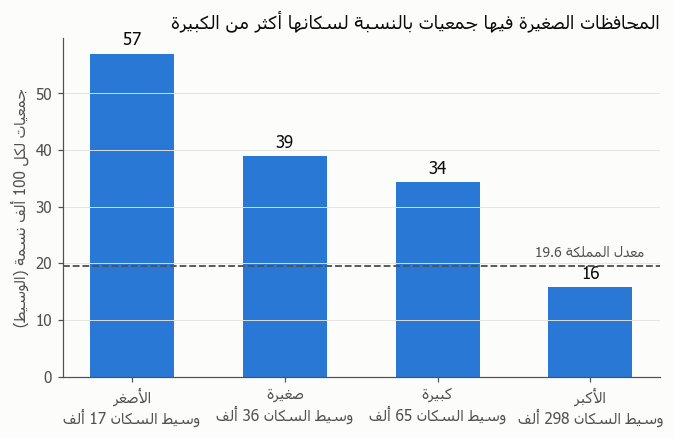

In [24]:
fig, ax = plt.subplots(figsize=(7, 4))
labels = [ar(name) + '\n' + ar(f'وسيط السكان {pop / 1000:,.0f} ألف') for name, pop in zip(by_size.index, by_size['population_median'])]
bars = ax.bar(labels, by_size['per_100k_median'], color=BLUE, width=0.55)
ax.bar_label(bars, fmt='%.0f', padding=3, color=INK, fontsize=11)
ax.axhline(NATIONAL_RATE, color=INK_2, linestyle='--', linewidth=1.2)
ax.text(3.35, NATIONAL_RATE + 1.5, ar(f'معدل المملكة {NATIONAL_RATE:.1f}'), color=INK_2, ha='right', fontsize=9)
ax.set_ylabel(ar('جمعيات لكل 100 ألف نسمة (الوسيط)'))
ax.set_title(ar('المحافظات الصغيرة فيها جمعيات بالنسبة لسكانها أكثر من الكبيرة'), color=INK, fontsize=12, loc='right')
ax.grid(axis='x', visible=False)
fig.savefig(FIGURES / 'fig1_rate_by_size.png')
plt.show()

**النتيجة:** المعدل ليس ثابتًا؛ المحافظات الأصغر فيها جمعيات لكل 100 ألف نسمة أكثر بكثير من الأكبر.
السبب المنطقي: كل محافظة تحتاج جمعيات أساسية (بر، تحفيظ، تنمية أهلية) مهما صغر حجمها، بينما الجمعية في المدينة الكبيرة تخدم عددًا أكبر من الناس.

لو استخدمنا النسبة الثابتة، ستظهر المدن الكبيرة كلها "ناقصة" والصغيرة كلها "مكتملة"، وهذا ناتج عن طريقة الحساب وليس عن احتياج حقيقي. لذلك نحتاج طريقة تقارن كل محافظة بالمحافظات التي في حجمها.

### 2. النموذج: خط يمثّل "الطبيعي" لكل حجم

**النموذج:** انحدار خطي بسيط بمتغير واحد (`LinearRegression` من مكتبة scikit-learn).

| | |
|---|---|
| **المدخل** | لوغاريتم عدد سكان المحافظة |
| **الهدف** | لوغاريتم عدد الجمعيات في المحافظة |
| **البيانات** | 150 محافظة (تعداد 2022) |
| **التحقق** | تحقق متقاطع بخمس طيّات (5-Fold Cross-Validation) + اختبار حساسية بدون مدينة الرياض |
| **المخرج** | العدد المتوقع لكل محافظة + نطاق طبيعي (فاصل تنبؤ 80%) |

**الفكرة ببساطة:** نرسم كل محافظة كنقطة (السكان مقابل عدد الجمعيات)، ونرسم **أفضل خط يمر بين النقاط**.
الخط يجيب: كم جمعية تكون عادةً في محافظة بهذا الحجم؟ والمحافظة التي تقع تحت الخط بكثير هي المرشحة للأولوية.

**لماذا نموذج وليس نسبة ثابتة؟** لأن النسبة الثابتة (الخطوة 1) متحيزة ضد المدن الكبيرة؛ النموذج **يقدّر العلاقة الفعلية من البيانات** بدل افتراضها، فيقارن كل محافظة بمثيلاتها في الحجم.

**لماذا نموذج بسيط؟** لدينا 150 محافظة ومتغير رئيسي واحد؛ النموذج الأعقد لا يضيف دقة هنا ويزيد خطر "حفظ" البيانات، بينما الانحدار الخطي **قابل للتفسير**: يمكن شرح نتيجته للمانحين برقم واحد (الميل). قوة التحليل في منطق المقارنة والتحقق منه، لا في تعقيد النموذج.

نستخدم **المقياس اللوغاريتمي** للمحورين لأن السكان يتراوحون من 7 آلاف إلى 7 ملايين؛ في هذا المقياس كل خطوة على المحور تعني "عشرة أضعاف"، فتظهر المحافظات الصغيرة والكبيرة بوضوح على رسم واحد.

**كيف نتأكد أن النموذج جيد؟**
- **الميل:** لو كانت النسبة الثابتة عادلة لكان الميل = 1. أي رقم أقل من 1 يعني أن الجمعيات تزيد أبطأ من السكان.
- **R²:** نسبة الاختلاف بين المحافظات التي يفسرها عدد السكان (من 0 إلى 1).
- **التحقق المتقاطع:** نقدّر الخط من 80% من المحافظات ونختبره على 20% لم تدخل في التقدير، ونكرر ذلك 5 مرات؛ إذا بقيت الدقة قريبة فالنموذج لا "يحفظ" البيانات بل يلتقط العلاقة فعلًا.

In [25]:
X = np.log(gov[['population']])
y = np.log(gov['npo_count'])
n = len(gov)

model = LinearRegression().fit(X, y)
log_pred = model.predict(X)
slope = model.coef_[0]

# 95% confidence interval for the slope
residual_sd = np.sqrt(((y - log_pred) ** 2).sum() / (n - 2))
x = X['population']
sxx = ((x - x.mean()) ** 2).sum()
slope_se = residual_sd / np.sqrt(sxx)
t95 = stats.t.ppf(0.975, n - 2)
print(f'Slope: {slope:.2f}  (95% CI {slope - t95 * slope_se:.2f} to {slope + t95 * slope_se:.2f}; 1.0 = fixed rate)')
print(f'Meaning: when population doubles, nonprofits grow by about {(2 ** slope - 1) * 100:.0f}%, not 100%')

print(f'\nR² (all governorates): {model.score(X, y):.2f}')
cv_r2 = cross_val_score(LinearRegression(), X, y, cv=KFold(5, shuffle=True, random_state=42), scoring='r2')
print(f'R² (5-fold cross-validation, unseen governorates): {cv_r2.mean():.2f} ± {cv_r2.std():.2f}')

# Sensitivity check: Riyadh city hosts the headquarters of most national organizations
no_riyadh = gov['governorate'] != 'الرياض'
slope_no_riyadh = LinearRegression().fit(X[no_riyadh], y[no_riyadh]).coef_[0]
print(f'\nSlope without Riyadh city: {slope_no_riyadh:.2f} (Riyadh city does not drive the result)')

Slope: 0.69  (95% CI 0.61 to 0.76; 1.0 = fixed rate)
Meaning: when population doubles, nonprofits grow by about 61%, not 100%

R² (all governorates): 0.67
R² (5-fold cross-validation, unseen governorates): 0.61 ± 0.11

Slope without Riyadh city: 0.67 (Riyadh city does not drive the result)


### 3. المتوقع لكل محافظة، والنطاق الطبيعي

- **المتوقع** = قيمة الخط عند حجم المحافظة.
- **النطاق الطبيعي** = المدى الذي تقع فيه 80% من المحافظات التي في نفس الحجم (فاصل التنبؤ 80%).
  الفرق الصغير عن المتوقع قد يكون صدفة؛ لذلك لا نعتبر المحافظة "أقل من المتوقع" إلا إذا كانت **تحت هذا النطاق**.

اخترنا 80% لأن الهدف **فرز أولي** يوجّه المانحين لدراسة الاحتياج، وليس حكمًا نهائيًا؛ ونعرض أيضًا المحافظات تحت نطاق 95% كأعلى درجات الأولوية.

In [26]:
se_pred = residual_sd * np.sqrt(1 + 1 / n + (x - x.mean()) ** 2 / sxx)
t80 = stats.t.ppf(0.90, n - 2)

gov['expected'] = np.exp(log_pred)
gov['expected_low'] = np.exp(log_pred - t80 * se_pred)
gov['expected_high'] = np.exp(log_pred + t80 * se_pred)
gov['gap'] = gov['npo_count'] - gov['expected']
gov['actual_vs_expected'] = gov['npo_count'] / gov['expected']

gov['status'] = 'ضمن الطبيعي'
gov.loc[gov['npo_count'] < gov['expected_low'], 'status'] = 'أقل من المتوقع بوضوح'
gov.loc[gov['npo_count'] > gov['expected_high'], 'status'] = 'أعلى من المتوقع بوضوح'
gov['below_95'] = gov['npo_count'] < np.exp(log_pred - t95 * se_pred)

display(gov['status'].value_counts().to_frame('governorates'))
print('\nBelow the 95% range (highest priority):', gov['below_95'].sum())

,governorates
status,
ضمن الطبيعي,122
أقل من المتوقع بوضوح,17
أعلى من المتوقع بوضوح,11



Below the 95% range (highest priority): 4


### 4. مقارنة الطريقتين

نطبّق الطريقتين على نفس المحافظات: النسبة الثابتة (المتوقع = السكان × معدل المملكة) والنموذج.

In [27]:
gov['expected_fixed'] = gov['population'] * NATIONAL_RATE / 100_000

examples = gov[gov['governorate'].isin(['جدة', 'تيماء'])].set_index('governorate')
display(examples[['population', 'npo_count', 'expected_fixed', 'expected', 'status']].round(0))

flagged_by_size = pd.DataFrame({
    'fixed_rate: below national rate': (gov['npo_count'] < gov['expected_fixed']).groupby(gov['size_group'], observed=True).sum(),
    'model: clearly below expected': (gov['status'] == 'أقل من المتوقع بوضوح').groupby(gov['size_group'], observed=True).sum(),
})
print('\nGovernorates flagged, by size group:')
flagged_by_size

,population,npo_count,expected_fixed,expected,status
governorate,,,,,
جدة,3751722,415,735.0,322.0,ضمن الطبيعي
تيماء,42165,6,8.0,15.0,أقل من المتوقع بوضوح



Governorates flagged, by size group:


,fixed_rate: below national rate,model: clearly below expected
size_group,,
الأصغر,3,5
صغيرة,4,3
كبيرة,8,3
الأكبر,23,6


**النتيجة:** النسبة الثابتة تصنّف معظم المحافظات الكبيرة كـ"ناقصة" ولا تكاد تصنّف أي محافظة صغيرة، بينما النموذج يوزّع المحافظات المحتاجة على كل الأحجام لأنه يقارن كل محافظة بمثيلاتها.
مثال: **جدة** تبدو ناقصة بالنسبة الثابتة، لكنها فوق المتوقع لحجمها؛ و**تيماء** تبدو قريبة من المعدل، لكنها أقل بكثير من المحافظات التي في حجمها.

### 5. أثر المنطقة

النموذج الوطني (الخطوتان 2 و3) يقارن كل محافظة **بمحافظات المملكة التي في حجمها**، وهو النموذج الرئيسي لأنه يجيب عن السؤال البحثي مباشرة.
هنا نضيف **طبقة ثانية**: هل تختلف المناطق نفسها؟ أي هل توجد مناطق كاملة فيها جمعيات أقل من المتوقع لحجم محافظاتها؟

1. **ملخص لكل منطقة** من النموذج الوطني: مجموع الموجود ÷ مجموع المتوقع.
2. **هل أثر المنطقة حقيقي؟** نموذج ثانٍ يضيف المنطقة (متغيرات وهمية لكل منطقة) إلى السكان، ونقارن الدقة ونختبر الفرق إحصائيًا (اختبار F).

In [28]:
by_region = gov.groupby('region').agg(
    governorates=('governorate', 'size'),
    population=('population', 'sum'),
    npo_count=('npo_count', 'sum'),
    expected=('expected', 'sum'),
    median_governorate_ratio=('actual_vs_expected', 'median'),
    below_expected=('status', lambda s: (s == 'أقل من المتوقع بوضوح').sum()),
)
by_region['actual_vs_expected'] = by_region['npo_count'] / by_region['expected']
by_region = by_region.sort_values('actual_vs_expected')[
    ['governorates', 'population', 'npo_count', 'expected', 'actual_vs_expected', 'median_governorate_ratio', 'below_expected']]
display(by_region.round({'expected': 0, 'actual_vs_expected': 2, 'median_governorate_ratio': 2}))

,governorates,population,npo_count,expected,actual_vs_expected,median_governorate_ratio,below_expected
region,,,,,,,
الجوف,4,595822,61,137.0,0.45,0.46,2
المنطقة الشرقية,12,5125254,509,753.0,0.68,0.49,5
تبوك,7,886036,142,183.0,0.77,0.67,2
جازان,17,1404997,301,370.0,0.81,0.64,5
نجران,7,592300,139,133.0,1.05,1.06,2
المدينة المنورة,9,2137983,380,338.0,1.12,0.98,0
عسير,18,2024285,535,450.0,1.19,1.27,0
الحدود الشمالية,4,373577,133,96.0,1.38,1.34,0
مكة المكرمة,17,8021463,1345,953.0,1.41,1.32,0


In [29]:
region_dummies = pd.get_dummies(gov['region'], prefix='region', drop_first=True).astype(int)
X_region = pd.concat([X, region_dummies], axis=1)
model_region = LinearRegression().fit(X_region, y)
log_pred_region = model_region.predict(X_region)

# Nested-model F-test: does adding region explain significantly more than population alone?
rss0 = ((y - log_pred) ** 2).sum()
rss1 = ((y - log_pred_region) ** 2).sum()
q = region_dummies.shape[1]
k = X_region.shape[1]
f_stat = ((rss0 - rss1) / q) / (rss1 / (n - k - 1))
p_value = stats.f.sf(f_stat, q, n - k - 1)

cv_r2_region = cross_val_score(LinearRegression(), X_region, y, cv=KFold(5, shuffle=True, random_state=42), scoring='r2')
model_comparison = pd.DataFrame({
    'R2': [model.score(X, y), model_region.score(X_region, y)],
    'R2_5fold_CV': [cv_r2.mean(), cv_r2_region.mean()],
    'slope_log_population': [slope, model_region.coef_[0]],
}, index=['population only', 'population + region'])
display(model_comparison.round(2))
print(f'F-test for adding region: F = {f_stat:.1f} (df {q}, {n - k - 1}), p = {p_value:.1e}')

,R2,R2_5fold_CV,slope_log_population
population only,0.67,0.61,0.69
population + region,0.83,0.74,0.76


F-test for adding region: F = 10.7 (df 12, 136), p = 9.3e-15


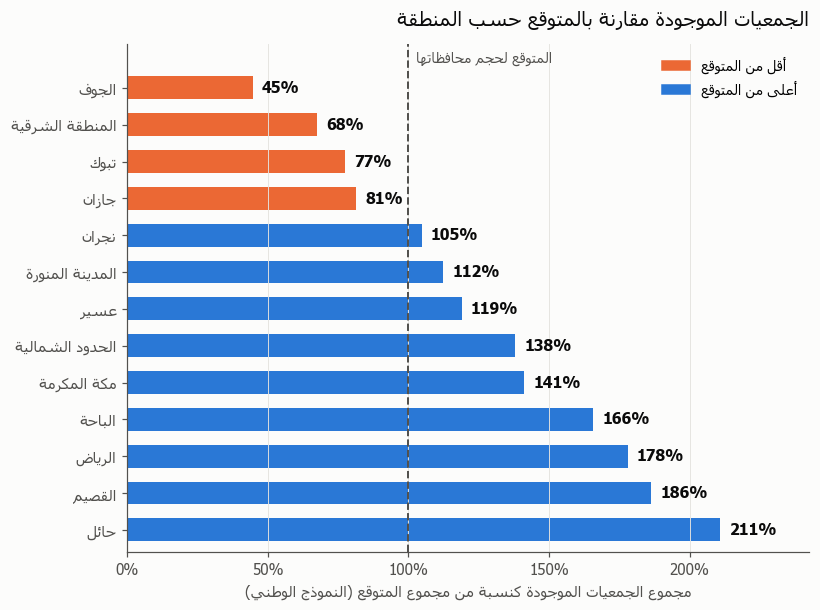

In [30]:
plot_region = by_region.sort_values('actual_vs_expected', ascending=False)
pct_region = plot_region['actual_vs_expected'] * 100
ypos = np.arange(len(plot_region))
colors = [ORANGE if p < 100 else BLUE for p in pct_region]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(ypos, pct_region, color=colors, height=0.62)
for yp, p in zip(ypos, pct_region):
    ax.annotate(f'{p:.0f}%', (p, yp), xytext=(6, 0), textcoords='offset points',
                va='center', fontsize=10, color=INK, fontweight='bold')
ax.axvline(100, color=INK_2, linestyle='--', linewidth=1.3)
ax.annotate(ar('المتوقع لحجم محافظاتها'), (100, len(plot_region) - 0.4), xytext=(5, 0), textcoords='offset points',
            ha='left', va='bottom', fontsize=9, color=INK_2)

ax.set_yticks(ypos, [ar(r) for r in plot_region.index], fontsize=10)
ax.set_xlim(0, pct_region.max() * 1.15)
ax.set_ylim(-0.6, len(plot_region) + 0.2)
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_xlabel(ar('مجموع الجمعيات الموجودة كنسبة من مجموع المتوقع (النموذج الوطني)'))
ax.grid(axis='y', visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ORANGE), plt.Rectangle((0, 0), 1, 1, color=BLUE)],
          labels=[ar('أقل من المتوقع'), ar('أعلى من المتوقع')], loc='upper right', frameon=False, fontsize=9)
ax.set_title(ar('الجمعيات الموجودة مقارنة بالمتوقع حسب المنطقة'), color=INK, fontsize=13, loc='right', pad=12)
fig.savefig(FIGURES / 'fig4_region_ratio.png')
plt.show()

**قراءة النتائج:**

- **المنطقة تفسّر جزءًا كبيرًا من الفجوة.** إضافة المنطقة إلى النموذج رفعت R² من 0.67 إلى 0.83، وعلى المحافظات التي لم يرها النموذج من 0.61 إلى 0.74؛ واختبار F يؤكد أن الفرق ليس صدفة (F = 10.7، p ≈ 9×10⁻¹⁵). ميل السكان بقي قريبًا (0.69 ← 0.76)، أي أن قاعدة "الجمعيات تزيد أبطأ من السكان" ثابتة في الحالتين.
- **مناطق كاملة أقل من المتوقع:** الجوف (45% من المتوقع)، المنطقة الشرقية (68%)، تبوك (77%)، جازان (81%). وفي الطرف الآخر حائل (211%) والقصيم (186%) والباحة (166%).
  نسبة الرياض (178%) مرتفعة بسبب مدينة الرياض التي تستضيف مقرات الجمعيات الوطنية؛ وسيط محافظاتها 0.98، أي أن المحافظة المعتادة في الرياض قريبة من المتوقع.
- **بعض الفجوات إقليمية:** 10 من محافظات قائمة الأولويات تقع في المنطقة الشرقية وجازان، وهما من المناطق الأقل من المتوقع ككل؛ أي أن جزءًا من الفجوة على مستوى **المنطقة كاملة** وليس محافظة واحدة. رسالة للمانحين الوطنيين وللمركز الوطني.
- **فرضية للمنطقة الشرقية (لم نختبرها):** المحافظات الصناعية مثل الجبيل ورأس تنورة وبقيق والنعيرية قد تكون فيها نسبة عالية من غير السعوديين، أو برامج مسؤولية اجتماعية تقدمها الشركات الكبرى، أو جمعيات تخدمها لكنها مسجلة في الدمام أو الخبر. لم نستخدم بيانات الجنسية على مستوى المحافظة، فهذه **فرضية تحتاج تحققًا** وليست نتيجة.
- **تنبيه:** بعض المناطق فيها محافظات قليلة (الجوف 4، الحدود الشمالية 4)، فمتوسط المنطقة فيها أقل ثباتًا.

**القائمة الرئيسية لا تتغير:** تبقى مبنية على النموذج الوطني (الخطوة 3) لأنها تجيب عن السؤال البحثي مباشرة؛ ونموذج المنطقة هنا يفسّر النتائج ولا يغيّر الترتيب.

### 6. قائمة الأولويات للمانحين

المحافظات التي عدد جمعياتها **تحت النطاق الطبيعي** لحجمها، مرتبة من الأشد نقصًا (أقل نسبة من المتوقع).
المحافظات المستحدثة عليها ملاحظة: قد تكون بعض جمعياتها ما زالت مسجلة تحت المحافظة الأم، فتحتاج تحققًا قبل القرار.

In [31]:
priority = gov[gov['status'] == 'أقل من المتوقع بوضوح'].sort_values('actual_vs_expected').copy()
priority['priority'] = np.where(priority['below_95'], 'عالية جدًا', 'عالية')
priority['note'] = np.where(priority['split_from'].notna(),
                            'محافظة مستحدثة: قد تكون بعض جمعياتها مسجلة في المحافظة الأم', '')
priority = priority[['region', 'governorate', 'population', 'npo_count', 'expected', 'expected_low',
                     'gap', 'actual_vs_expected', 'priority', 'note']].reset_index(drop=True)
priority.index += 1
priority.round({'expected': 1, 'expected_low': 1, 'gap': 1, 'actual_vs_expected': 2})

,region,governorate,population,npo_count,expected,expected_low,gap,actual_vs_expected,priority,note
1,المنطقة الشرقية,النعيرية,63815,2,19.7,8.8,-17.7,0.10,عالية جدًا,
2,المنطقة الشرقية,رأس تنورة,62314,3,19.4,8.6,-16.4,0.15,عالية جدًا,
3,المنطقة الشرقية,العديد,8635,1,5.0,2.2,-4.0,0.20,عالية جدًا,محافظة مستحدثة: قد تكون بعض جمعياتها مسجلة في المحافظة الأم
4,الجوف,طبرجل,109796,8,28.6,12.7,-20.6,0.28,عالية جدًا,محافظة مستحدثة: قد تكون بعض جمعياتها مسجلة في المحافظة الأم
5,المنطقة الشرقية,الجبيل,505162,24,81.3,35.9,-57.3,0.30,عالية,
6,نجران,ثار,13391,2,6.7,3.0,-4.7,0.30,عالية,
7,جازان,الطوال,36259,4,13.4,5.9,-9.4,0.30,عالية,محافظة مستحدثة: قد تكون بعض جمعياتها مسجلة في المحافظة الأم
8,المنطقة الشرقية,بقيق,64632,6,19.9,8.8,-13.9,0.30,عالية,
9,تبوك,البدع,17973,3,8.3,3.7,-5.3,0.36,عالية,محافظة مستحدثة: قد تكون بعض جمعياتها مسجلة في المحافظة الأم
10,تبوك,تيماء,42165,6,14.8,6.6,-8.8,0.40,عالية,


In [32]:
print('Priority governorates per region:')
display(priority['region'].value_counts().to_frame('governorates'))

priority.round(2).to_csv(OUTPUTS / 'priority_governorates.csv', index_label='rank', encoding='utf-8-sig')
(gov.drop(columns=['size_group'])
    .round({'per_100k': 1, 'expected': 1, 'expected_low': 1, 'expected_high': 1, 'gap': 1,
            'actual_vs_expected': 2, 'expected_fixed': 1})
    .to_csv(OUTPUTS / 'governorate_gap_analysis.csv', index=False, encoding='utf-8-sig'))
print('\nSaved:', OUTPUTS / 'priority_governorates.csv', '|', OUTPUTS / 'governorate_gap_analysis.csv')

Priority governorates per region:


,governorates
region,
المنطقة الشرقية,5
جازان,5
الجوف,2
نجران,2
تبوك,2
الرياض,1



Saved: outputs\priority_governorates.csv | outputs\governorate_gap_analysis.csv


### 7. نوع النقص: أي أنواع الجمعيات غائبة في محافظات الأولوية؟

قائمة الأولويات تقول **أين** التغطية منخفضة؛ لكن المانح يحتاج أن يعرف أيضًا **ما نوع** الكيانات الغائبة.
نحسب لكل محافظة عدد الكيانات في كل مجموعة من مجموعات التصنيف العشر، ثم نقارن محافظات الأولوية **بالمحافظات التي في حجمها** (نفس مجموعات الحجم الأربع من الخطوة 1)، لأن المحافظة الصغيرة بطبيعتها فيها أنواع أقل من المدن الكبيرة.

- **المدخل:** `data_clean/npo_all_regions_clean.csv`، نفس الكيانات المحسوبة على المحافظات (gov_status = ok أو manual).
- نستبعد **"منشأة بأمر ملكي"** لأنها ليست نوع خدمة.
- **نوع "شائع لهذا الحجم":** موجود في 50% أو أكثر من المحافظات في نفس مجموعة الحجم.
- **"غائب وشائع":** نوع شائع لحجم المحافظة لكن ليس فيها أي كيان منه.

In [33]:
npo_clean = pd.read_csv(CLEAN / 'npo_all_regions_clean.csv', dtype={'entity_id': str})
counted_npo = npo_clean[npo_clean['gov_status'].isin(['ok', 'manual'])]
print('Entities counted in governorates:', len(counted_npo))
royal = counted_npo['category'] == 'منشأة بأمر ملكي'
print('Excluded royal-decree entities (not a service type):', royal.sum())
counted_npo = counted_npo[~royal]

CATEGORY_SHORT = {
    'المجموعة الأولى الثقافة والترفيه': 'الثقافة والترفيه',
    'المجموعة الثانية التعليم والأبحاث': 'التعليم والأبحاث',
    'المجموعة الثالثة الصحة': 'الصحة',
    'المجموعة الرابعة الخدمات الاجتماعية': 'الخدمات الاجتماعية',
    'المجموعة الخامسة البيئة': 'البيئة',
    'المجموعة السادسة التنمية و الإسكان': 'التنمية والإسكان',
    'المجموعة السابعة التأييد والمؤازرة': 'التأييد والمؤازرة',
    'المجموعة الثامنة منظمات دعم العمل الخيري': 'دعم العمل الخيري',
    'المجموعة التاسعة منظمات الدعوة والإرشاد والتعليم الديني وخدمة ضيوف الرحمن': 'الدعوة والتعليم الديني',
    'المجموعة العاشرة الروابط المهنية': 'الروابط المهنية',
}
assert set(counted_npo['category']) == set(CATEGORY_SHORT), set(counted_npo['category']) ^ set(CATEGORY_SHORT)
counted_npo = counted_npo.assign(category_short=counted_npo['category'].map(CATEGORY_SHORT))
display(counted_npo['category_short'].value_counts().to_frame('entities'))

Entities counted in governorates: 6306
Excluded royal-decree entities (not a service type): 22


,entities
category_short,
الخدمات الاجتماعية,1594
التنمية والإسكان,1288
الدعوة والتعليم الديني,1142
الصحة,475
دعم العمل الخيري,421
التعليم والأبحاث,393
الثقافة والترفيه,348
البيئة,307
الروابط المهنية,214


In [34]:
# Governorate x category counts for all 150 governorates, columns ordered by national frequency
CATEGORY_ORDER = counted_npo['category_short'].value_counts().index.tolist()
matrix = (counted_npo.groupby(['region', 'governorate', 'category_short']).size()
          .unstack(fill_value=0).reindex(columns=CATEGORY_ORDER, fill_value=0))
gov_key = gov.set_index(['region', 'governorate'])
matrix = matrix.reindex(gov_key.index, fill_value=0)
assert len(matrix) == 150 and matrix.to_numpy().sum() == len(counted_npo)

gov['categories_present'] = (matrix > 0).sum(axis=1).values
print('Categories present per governorate (out of 10):')
print('  national median          :', gov['categories_present'].median())
print('  priority governorates    :', gov.loc[gov['status'] == 'أقل من المتوقع بوضوح', 'categories_present'].median())
print('  median by size group:')
print(gov.groupby('size_group', observed=True)['categories_present'].median().to_string())

Categories present per governorate (out of 10):
  national median          : 5.0
  priority governorates    : 3.0
  median by size group:
size_group
الأصغر    3.5
صغيرة     5.0
كبيرة     6.0
الأكبر    8.5


In [35]:
# Fair comparison: share of governorates in the SAME size group that have at least one entity of each type
has_category = (matrix > 0).assign(size_group=gov_key['size_group'])
share_by_size = has_category.groupby('size_group', observed=True)[CATEGORY_ORDER].mean()
COMMON_SHARE = 0.5
common = share_by_size >= COMMON_SHARE
print(f'Share of governorates with at least one entity, by size group (common = {COMMON_SHARE:.0%} or more):')
display(share_by_size.round(2))

Share of governorates with at least one entity, by size group (common = 50% or more):


category_short,الخدمات الاجتماعية,التنمية والإسكان,الدعوة والتعليم الديني,الصحة,دعم العمل الخيري,التعليم والأبحاث,الثقافة والترفيه,البيئة,الروابط المهنية,التأييد والمؤازرة
size_group,,,,,,,,,,
الأصغر,0.89,0.89,0.95,0.26,0.11,0.18,0.24,0.42,0.03,0.03
صغيرة,0.92,0.97,1.00,0.49,0.05,0.24,0.43,0.43,0.14,0.05
كبيرة,0.97,1.00,1.00,0.62,0.35,0.49,0.38,0.68,0.22,0.08
الأكبر,1.00,1.00,0.97,0.95,0.79,0.79,0.74,0.82,0.58,0.61


In [36]:
gap_rows, missing_flags = [], []
for rank, row in priority.iterrows():
    counts = matrix.loc[(row['region'], row['governorate'])]
    size = gov_key.loc[(row['region'], row['governorate']), 'size_group']
    missing = [c for c in CATEGORY_ORDER if common.loc[size, c] and counts[c] == 0]
    missing_flags.append({c: c in missing for c in CATEGORY_ORDER})
    gap_rows.append({
        'rank': rank, 'governorate': row['governorate'], 'region': row['region'], 'size_group': size,
        'npo_count': row['npo_count'], 'categories_present': int((counts > 0).sum()),
        'present_categories': '، '.join(f'{c} {counts[c]}' for c in CATEGORY_ORDER if counts[c] > 0),
        'missing_common': '، '.join(missing), 'n_missing_common': len(missing),
    })
category_gaps = pd.DataFrame(gap_rows)
missing_flags = pd.DataFrame(missing_flags, index=priority.index)
display(category_gaps)

category_gaps.to_csv(OUTPUTS / 'priority_category_gaps.csv', index=False, encoding='utf-8-sig')
priority['categories_present'] = category_gaps['categories_present'].values
priority['missing_common'] = category_gaps['missing_common'].values
priority.round(2).to_csv(OUTPUTS / 'priority_governorates.csv', index_label='rank', encoding='utf-8-sig')
print('Saved:', OUTPUTS / 'priority_category_gaps.csv', '| added 2 columns to', OUTPUTS / 'priority_governorates.csv')

,rank,governorate,region,size_group,npo_count,categories_present,present_categories,missing_common,n_missing_common
0,1,النعيرية,المنطقة الشرقية,كبيرة,2,2,التنمية والإسكان 1، الدعوة والتعليم الديني 1,الخدمات الاجتماعية، الصحة، البيئة,3
1,2,رأس تنورة,المنطقة الشرقية,كبيرة,3,3,الخدمات الاجتماعية 1، التنمية والإسكان 1، الدعوة والتعليم الديني 1,الصحة، البيئة,2
2,3,العديد,المنطقة الشرقية,الأصغر,1,1,الدعوة والتعليم الديني 1,الخدمات الاجتماعية، التنمية والإسكان,2
3,4,طبرجل,الجوف,الأكبر,8,3,الخدمات الاجتماعية 4، التنمية والإسكان 3، الصحة 1,الدعوة والتعليم الديني، دعم العمل الخيري، التعليم والأبحاث، الثقافة والترفيه...,7
4,5,الجبيل,المنطقة الشرقية,الأكبر,24,7,الخدمات الاجتماعية 8، التنمية والإسكان 4، الدعوة والتعليم الديني 5، دعم العم...,الصحة، البيئة، التأييد والمؤازرة,3
5,6,ثار,نجران,الأصغر,2,2,الخدمات الاجتماعية 1، التنمية والإسكان 1,الدعوة والتعليم الديني,1
6,7,الطوال,جازان,صغيرة,4,2,التنمية والإسكان 3، الدعوة والتعليم الديني 1,الخدمات الاجتماعية,1
7,8,بقيق,المنطقة الشرقية,كبيرة,6,4,الخدمات الاجتماعية 1، التنمية والإسكان 1، الدعوة والتعليم الديني 3، دعم العم...,الصحة، البيئة,2
8,9,البدع,تبوك,الأصغر,3,2,الخدمات الاجتماعية 1، الدعوة والتعليم الديني 2,التنمية والإسكان,1
9,10,تيماء,تبوك,صغيرة,6,3,الخدمات الاجتماعية 1، التنمية والإسكان 3، الدعوة والتعليم الديني 2,,0


Saved: outputs\priority_category_gaps.csv | added 2 columns to outputs\priority_governorates.csv


In [37]:
missing_summary = pd.DataFrame({
    'priority_governorates_missing': missing_flags.sum(),
    'common_in_size_groups': common.sum(),
}).sort_values('priority_governorates_missing', ascending=False)
print(f'For each type: in how many of the {len(priority)} priority governorates it is missing although common for their size')
display(missing_summary)

For each type: in how many of the 17 priority governorates it is missing although common for their size


,priority_governorates_missing,common_in_size_groups
البيئة,8,2
الخدمات الاجتماعية,4,4
التنمية والإسكان,4,4
الصحة,4,2
الروابط المهنية,4,1
التعليم والأبحاث,4,1
التأييد والمؤازرة,4,1
الدعوة والتعليم الديني,3,4
دعم العمل الخيري,3,1
الثقافة والترفيه,3,1


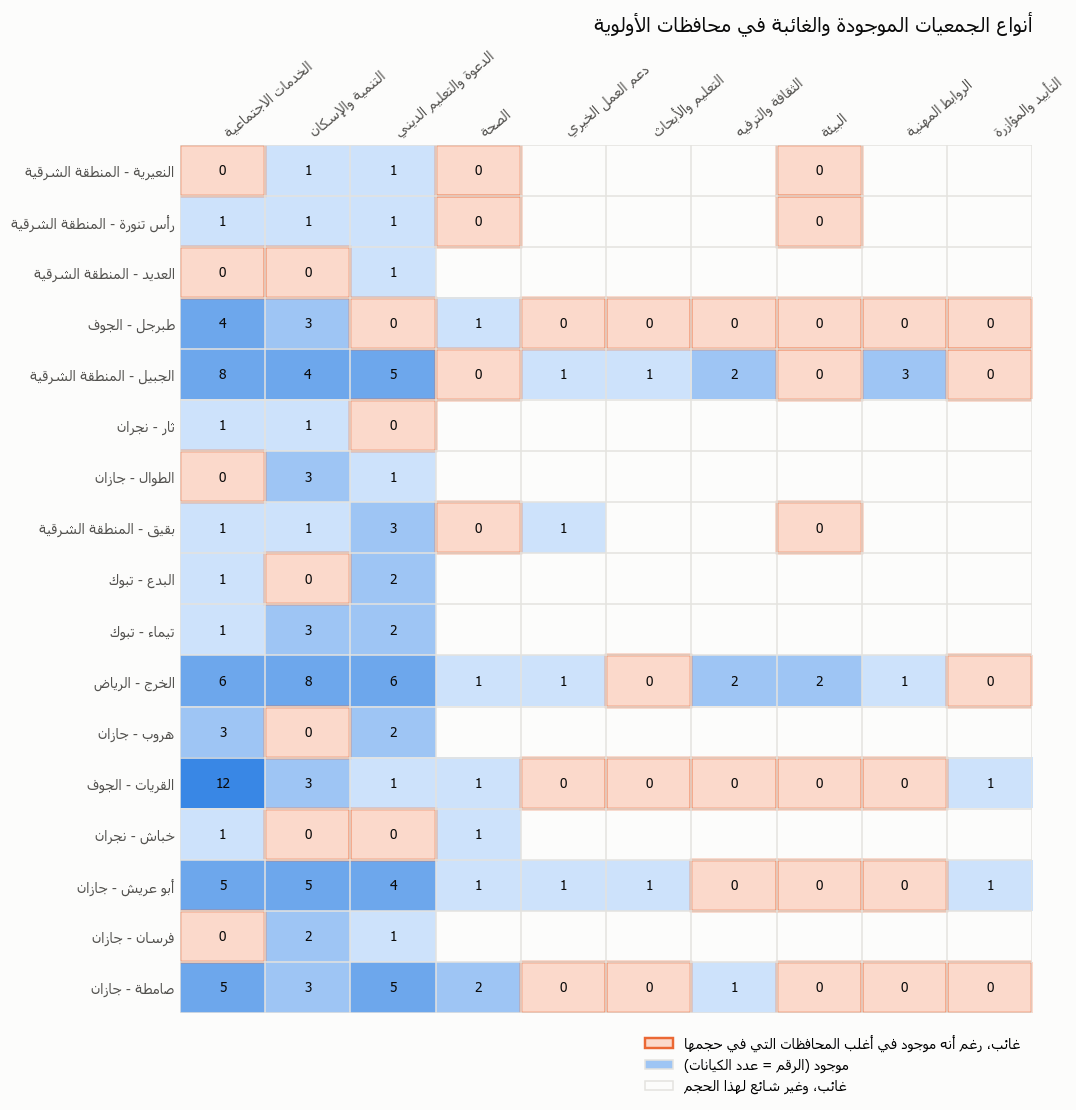

In [38]:
# Heatmap: priority governorates (same order as fig3) x categories (national frequency order)
heat = matrix.loc[list(zip(priority['region'], priority['governorate']))].to_numpy()
missing_common_cells = missing_flags.to_numpy()

BLUE_STEPS = ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5']  # 1, 2-3, 4-9, 10+
ORANGE_LIGHT = '#fbd9cb'
colors = np.empty(heat.shape, dtype=object)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat[i, j]
        if v > 0:
            colors[i, j] = BLUE_STEPS[0 if v == 1 else 1 if v <= 3 else 2 if v <= 9 else 3]
        else:
            colors[i, j] = ORANGE_LIGHT if missing_common_cells[i, j] else SURFACE
rgb = np.array([[mcolors.to_rgb(c) for c in r] for r in colors])

fig, ax = plt.subplots(figsize=(10, 0.45 * len(heat) + 2.6))
ax.imshow(rgb, aspect='auto')
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        if heat[i, j] > 0 or missing_common_cells[i, j]:
            ax.text(j, i, heat[i, j], ha='center', va='center', fontsize=9, color=INK)
        if missing_common_cells[i, j]:
            ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor=ORANGE, linewidth=1.6))
ax.set_xticks(np.arange(-0.5, heat.shape[1]), minor=True)
ax.set_yticks(np.arange(-0.5, heat.shape[0]), minor=True)
ax.grid(which='minor', color=GRID, linewidth=1)
ax.grid(which='major', visible=False)
ax.tick_params(which='both', length=0)
ax.set_xticks(range(len(CATEGORY_ORDER)), [ar(c) for c in CATEGORY_ORDER], rotation=40, ha='left', fontsize=9)
ax.xaxis.tick_top()
ax.set_yticks(range(len(priority)), [ar(f'{g} - {r}') for g, r in zip(priority['governorate'], priority['region'])], fontsize=9)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, facecolor=ORANGE_LIGHT, edgecolor=ORANGE, linewidth=1.6),
                   plt.Rectangle((0, 0), 1, 1, facecolor=BLUE_STEPS[1], edgecolor=GRID),
                   plt.Rectangle((0, 0), 1, 1, facecolor=SURFACE, edgecolor=GRID)],
          labels=[ar('غائب، رغم أنه موجود في أغلب المحافظات التي في حجمها'), ar('موجود (الرقم = عدد الكيانات)'),
                  ar('غائب، وغير شائع لهذا الحجم')],
          loc='upper right', bbox_to_anchor=(1.0, -0.01), ncol=1, frameon=False, fontsize=9)
ax.set_title(ar('أنواع الجمعيات الموجودة والغائبة في محافظات الأولوية'), color=INK, fontsize=13, loc='right', pad=12)
fig.savefig(FIGURES / 'fig5_priority_category_heatmap.png')
plt.show()

**قراءة النتائج:**

- **محافظات الأولوية فيها أنواع أقل:** المحافظة المعتادة في المملكة فيها 5 من 10 أنواع، بينما وسيط محافظات الأولوية 3 أنواع. لكن جزءًا من هذا طبيعي بسبب الحجم (وسيط الأنواع: 3.5 في أصغر المحافظات و8.5 في أكبرها)، لذلك قارنّا كل محافظة بالمحافظات التي في حجمها.
- **أكثر الأنواع غيابًا رغم أنها شائعة للحجم:** **البيئة** (غائبة في 8 من 17 محافظة)، ثم الخدمات الاجتماعية، والتنمية والإسكان، والصحة، والتعليم والأبحاث، والروابط المهنية، والتأييد والمؤازرة (4 محافظات لكل منها).
- **الصحة غائبة في 4 محافظات كلها في المنطقة الشرقية:** الجبيل وبقيق ورأس تنورة والنعيرية؛ وهذا يتسق مع فرضية المدن الصناعية في الخطوة 5.
- **أمثلة:**
  - **العديد:** كيان واحد فقط في الدعوة والتعليم الديني، ولا يوجد فيها خدمات اجتماعية ولا تنمية وإسكان، وهما موجودتان في أغلب المحافظات التي في حجمها.
  - **النعيرية:** كيانان فقط (تنمية وإسكان، ودعوة)، ولا يوجد فيها خدمات اجتماعية ولا صحة ولا بيئة.
  - **الجبيل** (أكثر من 500 ألف نسمة): 24 كيانًا في 7 أنواع، لكن لا يوجد فيها أي كيان صحي، بينما 95% من المحافظات التي في حجمها فيها كيان صحي واحد على الأقل.
- **صياغة التوصية للمانحين:** "محافظة الجبيل لا يوجد فيها أي كيان صحي، بينما أغلب المحافظات التي في حجمها فيها كيان صحي واحد على الأقل؛ نوصي **بدراسة الاحتياج الصحي** فيها". وليس "الجبيل تحتاج جمعية صحية"، لأن غياب النوع لا يعني بالضرورة غياب الخدمة.
- **ملاحظة على المحافظات الكبيرة:** في مجموعة الحجم الأكبر تقريبًا كل الأنواع العشرة "شائعة"، فتظهر محافظات مثل طبرجل والقريات وصامطة بعدد كبير من الأنواع الغائبة؛ الأهم فيها الأنواع الأساسية (الصحة، التعليم، الخدمات الاجتماعية).
- **حدود:** التصنيف هو التصنيف المسجّل للكيان؛ قد تقدم جمعية خدمات اجتماعية برامج صحية أو تعليمية، وقد تخدم كيانات في محافظات مجاورة هذه المنطقة.

### 8. الرسوم

**الرسم 2:** كل نقطة محافظة. الخط الأزرق هو المتوقع، والشريط حوله هو النطاق الطبيعي (80%).
النقاط البرتقالية تحت الشريط هي المحافظات الأقل من المتوقع بوضوح.

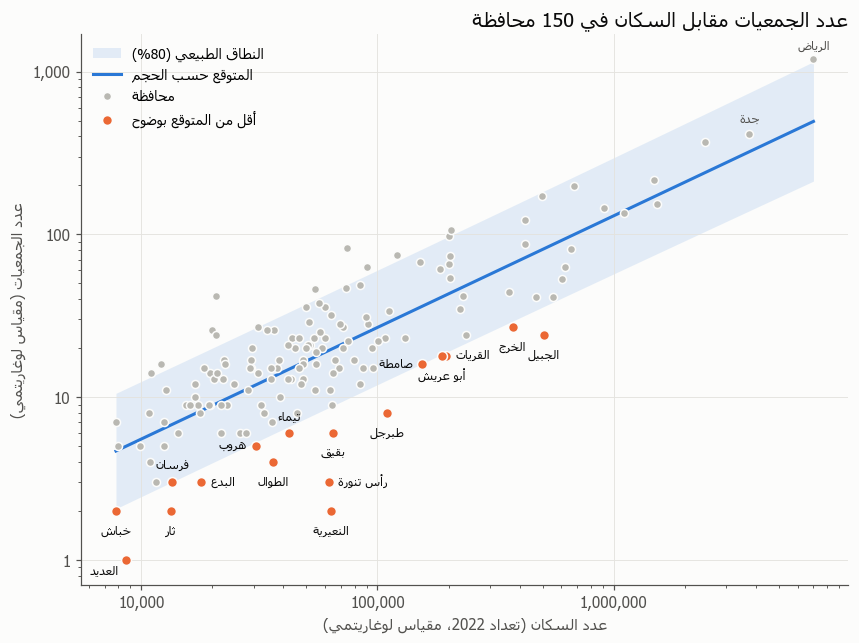

In [39]:
order = np.argsort(gov['population'].values)
pop_sorted = gov['population'].values[order]
below = gov['status'] == 'أقل من المتوقع بوضوح'

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.fill_between(pop_sorted, gov['expected_low'].values[order], gov['expected_high'].values[order],
                color=BLUE, alpha=0.12, linewidth=0, label=ar('النطاق الطبيعي (80%)'))
ax.plot(pop_sorted, gov['expected'].values[order], color=BLUE, linewidth=2, label=ar('المتوقع حسب الحجم'))
ax.scatter(gov.loc[~below, 'population'], gov.loc[~below, 'npo_count'], s=28, color=GRAY,
           edgecolor=SURFACE, linewidth=1, label=ar('محافظة'), zorder=3)
ax.scatter(gov.loc[below, 'population'], gov.loc[below, 'npo_count'], s=42, color=ORANGE,
           edgecolor=SURFACE, linewidth=1, label=ar('أقل من المتوقع بوضوح'), zorder=4)

# Label positions (dx, dy, ha, va) for points that sit close together; the rest go below their point
LABEL_OFFSETS = {
    'العديد': (-5, -3, 'right', 'top'),
    'هروب': (-6, 0, 'right', 'center'), 'تيماء': (0, 7, 'center', 'bottom'),
    'رأس تنورة': (6, 0, 'left', 'center'),
    'صامطة': (-6, 0, 'right', 'center'), 'القريات': (6, 0, 'left', 'center'),
    'فرسان': (0, 7, 'center', 'bottom'), 'البدع': (6, 0, 'left', 'center'),
}
assert set(LABEL_OFFSETS) <= set(gov.loc[below, 'governorate']), set(LABEL_OFFSETS) - set(gov.loc[below, 'governorate'])
for _, row in gov[below].iterrows():
    dx, dy, ha, va = LABEL_OFFSETS.get(row['governorate'], (0, -9, 'center', 'top'))
    ax.annotate(ar(row['governorate']), (row['population'], row['npo_count']), xytext=(dx, dy),
                textcoords='offset points', ha=ha, va=va, fontsize=8, color=INK)
for name in ['جدة', 'الرياض', 'تيماء']:
    row = gov.loc[gov['governorate'] == name].iloc[0]
    if row['status'] != 'أقل من المتوقع بوضوح':
        ax.annotate(ar(name), (row['population'], row['npo_count']), xytext=(0, 7),
                    textcoords='offset points', ha='center', fontsize=8, color=INK_2)

ax.set_xscale('log')
ax.set_yscale('log')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.set_xlabel(ar('عدد السكان (تعداد 2022، مقياس لوغاريتمي)'))
ax.set_ylabel(ar('عدد الجمعيات (مقياس لوغاريتمي)'))
ax.set_title(ar('عدد الجمعيات مقابل السكان في 150 محافظة'), color=INK, fontsize=13, loc='right')
ax.legend(loc='upper left', frameon=False, fontsize=9)
fig.savefig(FIGURES / 'fig2_population_vs_npo.png')
plt.show()

**الرسم 3:** لكل محافظة في قائمة الأولويات: **كم نسبة جمعياتها الموجودة من العدد المتوقع لحجمها.**
الخط المتقطع عند 100% يمثّل المتوقع؛ كلما قصر الشريط كانت الفجوة أكبر. مثال: النعيرية 10% تعني أن فيها جمعيتين فقط من 20 متوقعة لمحافظة بحجمها.

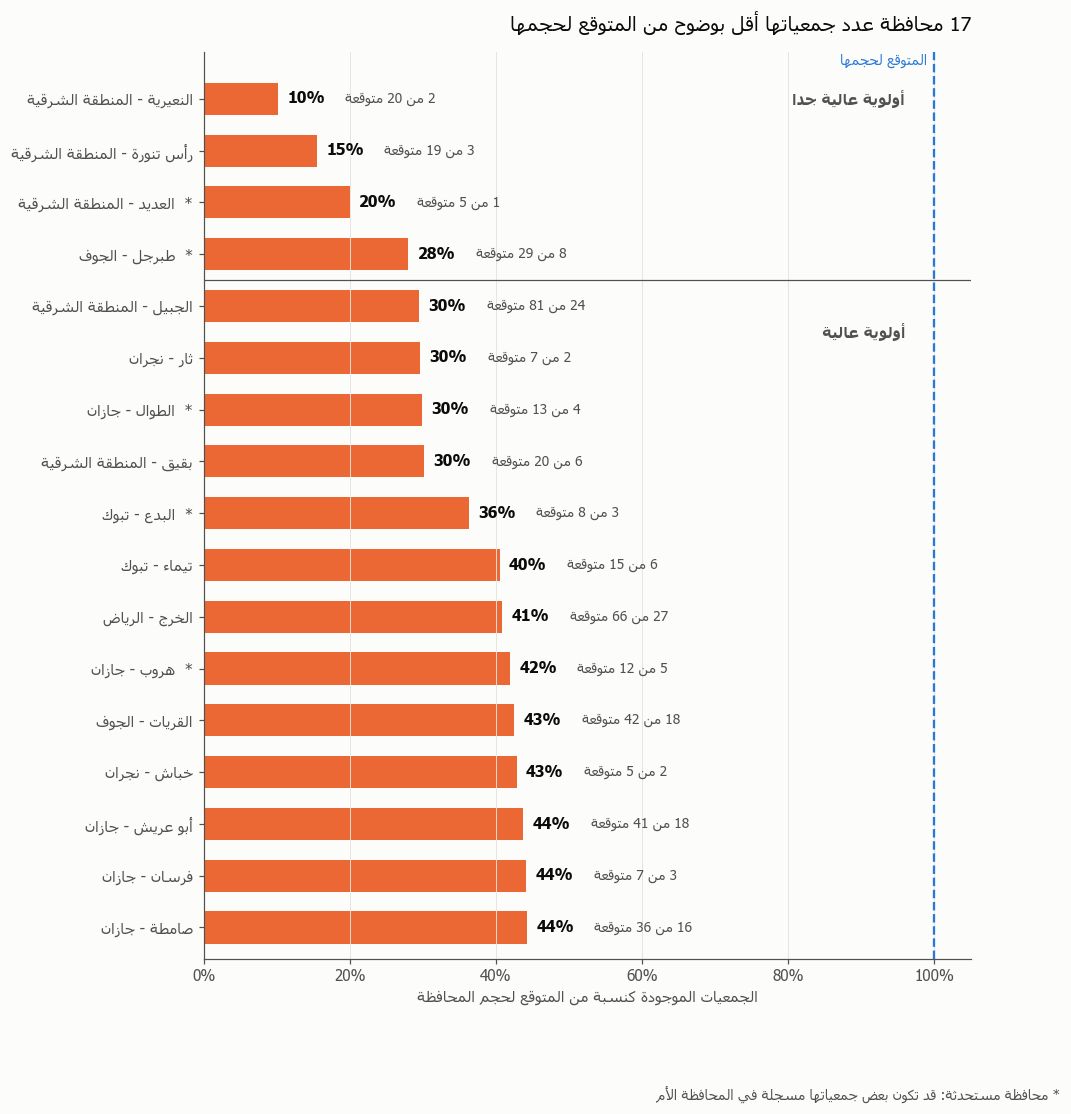

In [40]:
plot = priority.sort_values('actual_vs_expected', ascending=False).reset_index(drop=True)
pct = plot['actual_vs_expected'] * 100
ypos = np.arange(len(plot))
labels = [ar(f"{g} - {r}") + ('  *' if note else '') for g, r, note in zip(plot['governorate'], plot['region'], plot['note'])]

fig, ax = plt.subplots(figsize=(9, 0.5 * len(plot) + 2.2))
ax.barh(ypos, pct, color=ORANGE, height=0.62)
for yp, p, actual, expected in zip(ypos, pct, plot['npo_count'], plot['expected']):
    ax.annotate(f'{p:.0f}%', (p, yp), xytext=(6, 0), textcoords='offset points',
                va='center', fontsize=10, color=INK, fontweight='bold')
    ax.annotate(ar(f'{actual} من {expected:.0f} متوقعة'), (p, yp), xytext=(44, 0), textcoords='offset points',
                va='center', fontsize=9, color=INK_2)

ax.axvline(100, color=BLUE, linestyle='--', linewidth=1.5)
ax.annotate(ar('المتوقع لحجمها'), (100, len(plot) - 0.4), xytext=(-5, 0), textcoords='offset points',
            ha='right', va='bottom', fontsize=9, color=BLUE)

# Separate the highest-priority group (below the 95% range) from the rest
n_very_high = (plot['priority'] == 'عالية جدًا').sum()
split = len(plot) - n_very_high - 0.5
ax.axhline(split, color=INK_2, linewidth=0.8)
ax.text(96, len(plot) - 1, ar('أولوية عالية جدًا'), ha='right', va='center', fontsize=10, color=INK_2, fontweight='bold')
ax.text(96, split - 1, ar('أولوية عالية'), ha='right', va='center', fontsize=10, color=INK_2, fontweight='bold')

ax.set_yticks(ypos, labels, fontsize=10)
ax.set_xlim(0, 105)
ax.set_ylim(-0.6, len(plot) - 0.1)
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_xlabel(ar('الجمعيات الموجودة كنسبة من المتوقع لحجم المحافظة'))
ax.grid(axis='y', visible=False)
ax.set_title(ar(f'{len(plot)} محافظة عدد جمعياتها أقل بوضوح من المتوقع لحجمها'), color=INK, fontsize=13, loc='right', pad=14)
fig.text(0.99, -0.01, ar('* محافظة مستحدثة: قد تكون بعض جمعياتها مسجلة في المحافظة الأم'),
         ha='right', fontsize=9, color=INK_2)
fig.savefig(FIGURES / 'fig3_priority_governorates.png')
plt.show()

**الرسم 6 (خريطة):** حالة كل محافظة على الخريطة. حدود المحافظات من **geoBoundaries** (SAU ADM2، نسخة مبسطة) وحدود المناطق من geoBoundaries ADM1، محفوظة في `data_raw/geo/` ويقرؤها الدفتر من الجهاز فقط.
أسماء المضلعات بالإنجليزية، فنطابقها مع محافظاتنا الـ150 بقاموس صريح `GOVERNORATE_SHAPES`. ثلاث محافظات ليس لها مضلع مستقل في ملف الحدود (`None`): الدمام والمويه (ضمن الطبيعي) والأمواه (أعلى من المتوقع)، وليست أي منها في قائمة الأولويات؛ مكان الدمام يظهر فارغًا على الخريطة.

**تنبيه في قراءة الخريطة:** حدود المحافظات في geoBoundaries مأخوذة من OpenStreetMap وقد لا تطابق الحدود الرسمية في المناطق الصحراوية (مثل الربع الخالي)، لذلك يظهر خط حدود المنطقة الشرقية مع الرياض مخالفًا لبعض المضلعات، وتظهر محافظة العديد بمساحة كبيرة. **مساحة المحافظة على الخريطة لا تعكس عدد سكانها**؛ الأهم هو اللون.

In [41]:
GOVERNORATE_SHAPES = {
    # الباحة
    'العقيق': 'Al Aqiq', 'الباحة': 'Al Bahah', 'الحجرة': 'Al Hajrah', 'المخواة': 'Al Mukhwah',
    'المندق': 'Al Mandaq', 'القرى': 'Al Qara', 'بلجرشي': 'Biljurashi', 'بني حسن': 'Bani Hasan',
    'فرعة غامد الزناد': 'Farat Ghamid Az Zinad', 'قلوة': 'Qilwah',
    # الحدود الشمالية
    'العويقيلة': 'Al Uwayqilah', 'عرعر': 'Arar', 'رفحاء': 'Rafha', 'طريف': 'Turayf',
    # الجوف
    'القريات': 'Al Qurayyat', 'دومة الجندل': 'Dawamat Al Jandal', 'سكاكا': 'Sakaka', 'طبرجل': 'Tubarjal',
    # المدينة المنورة
    'العيص': 'Al Is', 'الحناكية': 'Al Hinakiyah', 'المدينة المنورة': 'Al Madinah Al Munawwarah', 'العلا': 'Al Ula',
    'بدر': 'Badr', 'خيبر': 'Khaybar', 'مهد الذهب': 'Al Mahd', 'وادي الفرع': 'Wadi Al Fara',
    'ينبع البحر': 'Yanbu',
    # القصيم
    'الأسياح': 'Al Asyah', 'البدائع': 'Al Badai', 'البكيرية': 'Al Bukayriyah', 'المذنب': 'Al Midhnab',
    'النبهانية': 'An Nabhaniyah', 'الرس': 'Ar Rass', 'الشماسية': 'Ash Shimasiyah', 'بريدة': 'Buraydah',
    'ضرية': 'Dariyah', 'رياض الخبراء': 'Riyadh Al Khabra', 'عنيزة': 'Unayzah', 'عقلة الصقور': 'Uqlat As Suqur',
    'عيون الجواء': 'Uyun Al Jiwa',
    # الرياض
    'الدوادمي': 'Ad Duwadimi', 'الدلم': 'Ad Dilam', 'الدرعية': 'Ad Diriyah', 'عفيف': 'Afif',
    'الأفلاج': 'Al Aflaj', 'الغاط': 'Al Ghat', 'الحريق': 'Al Hariq', 'الخرج': 'Al Kharj',
    'المجمعة': 'Al Majmaah', 'المزاحمية': 'Al Muzahimiyah', 'القويعية': 'Al Quwayiyah', 'الرين': 'Ar Rayn',
    'الرياض': 'Riyadh', 'السليل': 'As Sulayyil', 'الزلفي': 'Az Zulfi', 'ضرما': 'Duruma',
    'حوطة بني تميم': 'Hawtat Bani Tamim', 'حريملاء': 'Huraymila', 'مرات': 'Marat', 'رماح': 'Rumah',
    'شقراء': 'Shaqra', 'ثادق': 'Thadiq', 'وادي الدواسر': 'Wadi Ad Dawasir',
    # المنطقة الشرقية
    'بقيق': 'Abqaiq Governorate', 'الدمام': None, 'الأحساء': 'Al Ahsa Governorate', 'الجبيل': 'Al Jubayl Governorate',
    'الخفجي': 'Al Khafji Governorate', 'الخبر': 'Al Khubar Governorate', 'القطيف': 'Al Qatif Governorate', 'العديد': 'Al Udayd Governorate',
    'النعيرية': 'Al Nuayriyah Governorate', 'حفر الباطن': 'Hafar Al Batin Governorate', 'قرية العليا': 'Qaryah Al Ulya Governorate', 'رأس تنورة': 'Ras Tannurah Governorate',
    # عسير
    'أبها': 'Abha', 'أحد رفيدة': 'Ahad Rufaydah', 'الأمواه': None, 'البرك': 'Al Birk',
    'الحرجة': 'Al Harjah', 'المجاردة': 'Al Majardah', 'النماص': 'An Namas', 'بالقرن': 'Balqarn',
    'بارق': 'Bariq', 'بيشة': 'Bishah', 'خميس مشيط': 'Khamis Mushayt', 'محايل': 'Muhayil',
    'رجال ألمع': 'Rijal Al Ma', 'سراة عبيدة': 'Sarat Abidah', 'تنومة': 'Tanumah', 'طريب': 'Tarib',
    'تثليث': 'Tathlith', 'ظهران الجنوب': 'Zahran Al Janub',
    # حائل
    'الغزالة': 'Al Ghazalah', 'الحائط': 'Al Hait', 'الشملي': 'Ash Shamli', 'الشنان': 'Ash Shinan',
    'السليمي': 'As Sulaymi', 'بقعاء': 'Baqa', 'حائل': 'Hail', 'موقق': 'Mawqaq',
    'سميراء': 'Simira',
    # جازان
    'أبو عريش': 'Abu Arish', 'الدرب': 'Ad Darb', 'الدائر': 'Ad Dair', 'أحد المسارحة': 'Ahad Al Masarihah',
    'العارضة': 'Al Aridah', 'العيدابي': 'Al Aydabi', 'الحرث': 'Al Harth', 'الريث': 'Ar Rayth',
    'الطوال': 'At Tuwal', 'بيش': 'Baysh', 'ضمد': 'Damad', 'فرسان': 'Farasan',
    'فيفا': 'Fayfa', 'هروب': 'Harub', 'جيزان': 'Jazan', 'صبيا': 'Sabya',
    'صامطة': 'Samtah',
    # مكة المكرمة
    'أضم': 'Adam', 'العرضيات': 'Al Ardiyat', 'الجموم': 'Al Jumum', 'الكامل': 'Al Kamil',
    'الخرمة': 'Al Khurmah', 'الليث': 'Al Lith', 'المويه': None, 'القنفذة': 'Al Qunfudhah',
    'الطائف': 'Al Taif', 'بحرة': 'Bahrah', 'جدة': 'Jiddah', 'خليص': 'Khulays',
    'مكة المكرمة': 'Makkah Al Mukarramah', 'ميسان': 'Maysan', 'رابغ': 'Rabigh', 'رنية': 'Ranyah',
    'تربة': 'Turubah',
    # نجران
    'بدر الجنوب': 'Badr Al Janub', 'حبونا': 'Hubuna', 'خباش': 'Khubash', 'نجران': 'Najran',
    'شرورة': 'Sharurah', 'ثار': 'Thar', 'يدمة': 'Yadamah',
    # تبوك
    'البدع': 'Al Bad', 'الوجه': 'Al Wajh', 'ضباء': 'Duba', 'حقل': 'Haqil',
    'تبوك': 'Tabuk', 'تيماء': 'Tayma', 'أملج': 'Umluj',
}

GEO = RAW / 'geo'
adm2 = json.load(open(GEO / 'geoBoundaries-SAU-ADM2_simplified.geojson', encoding='utf-8'))['features']
adm1 = json.load(open(GEO / 'geoBoundaries-SAU-ADM1_simplified.geojson', encoding='utf-8'))['features']

assert set(GOVERNORATE_SHAPES) == set(gov['governorate'])
shape_names = {f['properties']['shapeName'] for f in adm2}
mapped = [s for s in GOVERNORATE_SHAPES.values() if s]
assert len(mapped) == len(set(mapped)), 'one polygon per governorate'
print('Polygons:', len(shape_names), '| governorates matched:', len(mapped), 'of', len(GOVERNORATE_SHAPES))
print('Governorates without a polygon:', [g for g, s in GOVERNORATE_SHAPES.items() if s is None])
print('Polygons without a governorate:', sorted(shape_names - set(mapped)))
print('Status of governorates without a polygon:',
      gov.loc[gov['governorate'].isin([g for g, s in GOVERNORATE_SHAPES.items() if s is None]), 'status'].to_dict())

Polygons: 147 | governorates matched: 147 of 150
Governorates without a polygon: ['الدمام', 'الأمواه', 'المويه']
Polygons without a governorate: []
Status of governorates without a polygon: {64: 'ضمن الطبيعي', 77: 'أعلى من المتوقع بوضوح', 125: 'ضمن الطبيعي'}


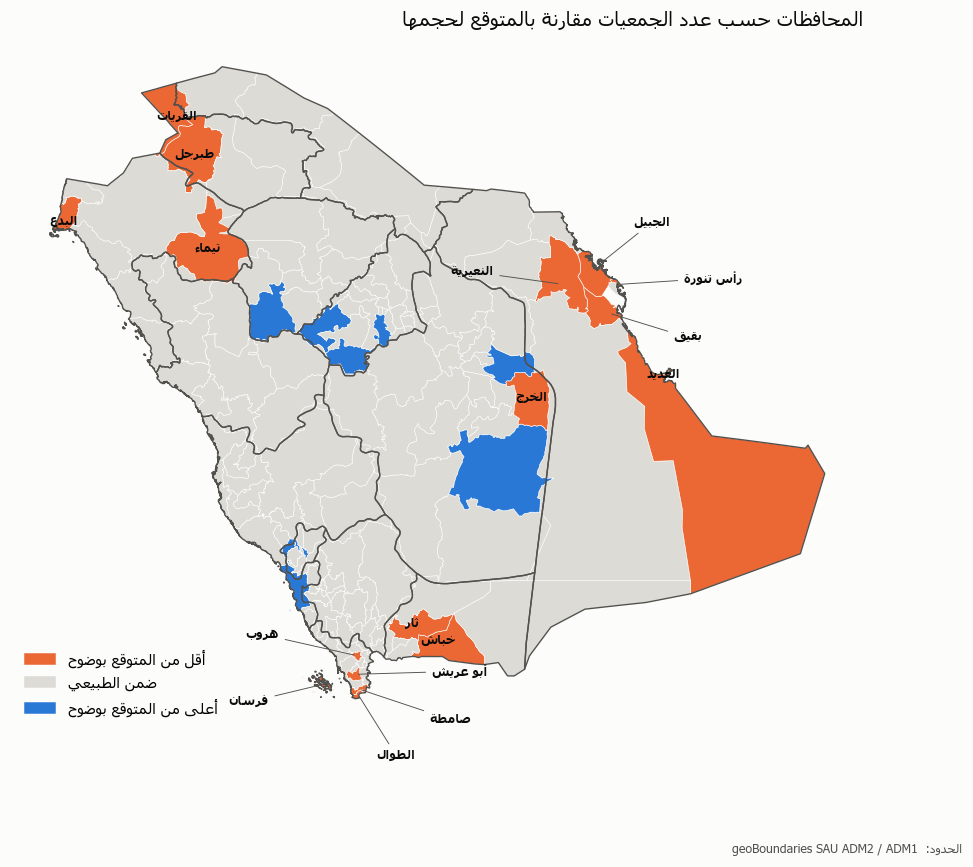

In [42]:
STATUS_COLOR = {'أقل من المتوقع بوضوح': ORANGE, 'ضمن الطبيعي': '#dcdbd6', 'أعلى من المتوقع بوضوح': BLUE}
status_by_shape = {GOVERNORATE_SHAPES[g]: s for g, s in zip(gov['governorate'], gov['status']) if GOVERNORATE_SHAPES[g]}
shape_to_governorate = {s: g for g, s in GOVERNORATE_SHAPES.items() if s}
priority_names = set(priority['governorate'])

patches, colors, label_points = [], [], {}
for feature in adm2:
    geometry = feature['geometry']
    polygons = geometry['coordinates'] if geometry['type'] == 'MultiPolygon' else [geometry['coordinates']]
    name = feature['properties']['shapeName']
    for polygon in polygons:
        patches.append(MplPolygon(polygon[0], closed=True))
        colors.append(STATUS_COLOR[status_by_shape[name]])
    largest = max(polygons, key=lambda p: len(p[0]))
    label_points[shape_to_governorate[name]] = np.array(largest[0]).mean(axis=0)

region_patches = []
for feature in adm1:
    geometry = feature['geometry']
    polygons = geometry['coordinates'] if geometry['type'] == 'MultiPolygon' else [geometry['coordinates']]
    region_patches += [MplPolygon(polygon[0], closed=True) for polygon in polygons]

fig, ax = plt.subplots(figsize=(10, 9))
ax.add_collection(PatchCollection(patches, facecolor=colors, edgecolor=SURFACE, linewidth=0.4))
ax.add_collection(PatchCollection(region_patches, facecolor='none', edgecolor=INK_2, linewidth=0.9))

# Label positions (dx, dy in points) for crowded areas; the rest sit on the polygon centre
MAP_LABEL_OFFSETS = {
    'الجبيل': (35, 28), 'رأس تنورة': (62, 4), 'النعيرية': (-58, 8), 'بقيق': (52, -16),
    'هروب': (-62, 14), 'أبو عريش': (68, 2), 'صامطة': (60, -20), 'الطوال': (25, -40), 'فرسان': (-50, -12),
}
assert set(MAP_LABEL_OFFSETS) <= priority_names
for name in priority_names:
    x0, y0 = label_points[name]
    dx, dy = MAP_LABEL_OFFSETS.get(name, (0, 0))
    ax.annotate(ar(name), (x0, y0), xytext=(dx, dy), textcoords='offset points', ha='center', va='center',
                fontsize=8, color=INK, fontweight='bold',
                arrowprops=dict(arrowstyle='-', color=INK_2, linewidth=0.6) if (dx, dy) != (0, 0) else None)

ax.autoscale_view()
ax.set_aspect(1 / np.cos(np.radians(24)))  # degrees -> roughly equal distances at Saudi latitudes
ax.axis('off')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=STATUS_COLOR[s]) for s in STATUS_COLOR],
          labels=[ar(s) for s in STATUS_COLOR], loc='lower left', frameon=False, fontsize=10)
ax.set_title(ar('المحافظات حسب عدد الجمعيات مقارنة بالمتوقع لحجمها'), color=INK, fontsize=13, loc='right')
fig.text(0.99, 0.02, 'geoBoundaries SAU ADM2 / ADM1  ' + ar('الحدود:'), ha='right', fontsize=8, color=INK_2)
fig.savefig(FIGURES / 'fig6_map.png')
plt.show()

---
### 9. الداشبورد التفاعلية

صفحة HTML واحدة (`outputs/dashboard.html`) لاستكشاف النتائج على خريطة المحافظات: التلوين بالحالة أو بنسبة الموجود من المتوقع، وتفاصيل كل محافظة (الأرقام، الأنواع الغائبة، وأسماء الكيانات)، وقائمة الأولويات مع تصفية بالمنطقة.

- **مكمّلة للدفتر وليست بديلًا عنه:** تُبنى من نفس النتائج أعلاه، فلا تغيّر أي رقم أو ترتيب.
- **تعمل بدون إنترنت:** ملف واحد يُفتح بالنقر المزدوج، والبيانات مضمّنة فيه؛ بدون مكتبات أو خطوط أو خرائط خارجية.
- التصميم (HTML/CSS/JavaScript) في `dashboard/template.html`، وهذه الخلية تحوّل حدود المحافظات إلى مسارات SVG وتضع البيانات داخل القالب.

In [43]:
TEMPLATE = Path('dashboard') / 'template.html'
DASHBOARD = OUTPUTS / 'dashboard.html'

# Equirectangular projection to an SVG 1000 units wide (longitude shrunk by cos 24°, as in the map figure)
points = np.array([pt for f in adm2 for polygon in (f['geometry']['coordinates'] if f['geometry']['type'] == 'MultiPolygon'
                   else [f['geometry']['coordinates']]) for pt in polygon[0]])
KX = np.cos(np.radians(24))
lon_min, lat_max = points[:, 0].min(), points[:, 1].max()
SCALE = 1000 / ((points[:, 0].max() - lon_min) * KX)
svg_height = (lat_max - points[:, 1].min()) * SCALE

def project(geometry):
    polygons = geometry['coordinates'] if geometry['type'] == 'MultiPolygon' else [geometry['coordinates']]
    return [[((lon - lon_min) * KX * SCALE, (lat_max - lat) * SCALE) for lon, lat in polygon[0]] for polygon in polygons]

def svg_path(rings):
    return ''.join('M' + 'L'.join(f'{x:.1f},{y:.1f}' for x, y in ring) + 'Z' for ring in rings)

def bbox(rings):
    xy = np.array([pt for ring in rings for pt in ring])
    return [round(float(v), 1) for v in (*xy.min(axis=0), *(xy.max(axis=0) - xy.min(axis=0)))]

shape_rings = {f['properties']['shapeName']: project(f['geometry']) for f in adm2}
region_paths = [svg_path(project(f['geometry'])) for f in adm1]

# Entities per governorate: [name, category index (-1 = royal decree), entity type index]
ROYAL = 'منشأة بأمر ملكي'
resolved_npo = npo_clean[npo_clean['gov_status'].isin(['ok', 'manual'])]
TYPES = sorted(resolved_npo['entity_type'].unique())
category_index = {c: k for k, c in enumerate(CATEGORY_ORDER)}
entities = {key: [[row['entity_name'], -1 if row['category'] == ROYAL else category_index[CATEGORY_SHORT[row['category']]],
                   TYPES.index(row['entity_type'])] for _, row in group.sort_values('entity_name').iterrows()]
            for key, group in resolved_npo.groupby(['region', 'governorate'])}

parent_ar = dict(zip(pop['name_en'].str.replace(r'\s*\[.*\]', '', regex=True), pop['governorate']))
priority_by_name = {row['governorate']: (rank, row['priority']) for rank, row in priority.iterrows()}

SIZE_GROUPS = list(gov['size_group'].cat.categories)
size_medians = matrix.groupby(gov_key['size_group'], observed=True).median().reindex(SIZE_GROUPS)

# Model line and 80% band for the interactive scatter (same formulas as steps 2-3)
grid = np.geomspace(gov['population'].min() * 0.9, gov['population'].max() * 1.1, 60)
grid_log = np.log(grid)
grid_pred = model.intercept_ + slope * grid_log
grid_se = residual_sd * np.sqrt(1 + 1 / n + (grid_log - x.mean()) ** 2 / sxx)
model_line = [[round(float(p)), round(float(np.exp(m)), 2), round(float(np.exp(m - t80 * s)), 2), round(float(np.exp(m + t80 * s)), 2)]
              for p, m, s in zip(grid, grid_pred, grid_se)]

govs_json = []
for _, row in gov.iterrows():
    key = (row['region'], row['governorate'])
    counts = matrix.loc[key]
    rank, level = priority_by_name.get(row['governorate'], (None, None))
    shape = GOVERNORATE_SHAPES[row['governorate']]
    govs_json.append({
        'region': row['region'], 'name': row['governorate'], 'population': int(row['population']),
        'npo': int(row['npo_count']), 'expected': int(round(row['expected'])), 'pct': int(round(row['actual_vs_expected'] * 100)),
        'per100k': round(float(row['per_100k']), 1), 'status': row['status'], 'rank': rank, 'level': level,
        'split_from': parent_ar.get(row['split_from'], row['split_from']) if isinstance(row['split_from'], str) else None,
        'cats': [int(counts[c]) for c in CATEGORY_ORDER],
        'royal': sum(e[1] == -1 for e in entities.get(key, [])),
        'missing': [c for c in CATEGORY_ORDER if common.loc[gov_key.loc[key, 'size_group'], c] and counts[c] == 0],
        'entities': entities.get(key, []),
        'path': svg_path(shape_rings[shape]) if shape else None,
        'bbox': bbox(shape_rings[shape]) if shape else None,
        'size': SIZE_GROUPS.index(row['size_group']),
        'lowPct': int(round(row['expected_low'] / row['expected'] * 100)),
        'highPct': int(round(row['expected_high'] / row['expected'] * 100)),
    })

dashboard_data = {
    'kpis': {'governorates': len(gov), 'entities': int(gov['npo_count'].sum()),
             'unassigned': int((npo['gov_status'] == 'unresolved').sum()), 'priority': len(priority),
             'national_rate': round(float(NATIONAL_RATE), 1), 'name_fixed': n_fix},
    'sizeGroups': SIZE_GROUPS,
    'sizeMedians': [[float(v) for v in size_medians.loc[s, CATEGORY_ORDER]] for s in SIZE_GROUPS],
    'model': {'line': model_line, 'slope': round(float(slope), 2), 'doubling': int(round((2 ** slope - 1) * 100)),
              'r2': round(float(model.score(X, y)), 2), 'cv_r2': round(float(cv_r2.mean()), 2)},
    'categories': CATEGORY_ORDER,
    'types': TYPES,
    'regions': [{'name': region, 'pct': int(round(r['actual_vs_expected'] * 100)),
                 'priority': int((priority['region'] == region).sum())} for region, r in by_region.iterrows()],
    'viewBox': f'0 0 1000 {svg_height:.0f}',
    'regionPaths': region_paths,
    'govs': govs_json,
}

# Checks: same governorates, entities and priority list as the analysis
assert len(govs_json) == 150
assert sum(g['npo'] for g in govs_json) == gov['npo_count'].sum() == 6306
assert sum(g['rank'] is not None for g in govs_json) == len(priority) == 17
assert all(len(g['entities']) == g['npo'] for g in govs_json), 'entity list must match npo_count'

# 'missing but common' is computed for all 150 governorates; for the 17 it must match step 7
gaps = pd.read_csv(OUTPUTS / 'priority_category_gaps.csv')
for _, r in gaps.iterrows():
    step7 = [] if pd.isna(r['missing_common']) else r['missing_common'].split('، ')
    g = next(x for x in govs_json if x['region'] == r['region'] and x['name'] == r['governorate'])
    assert g['missing'] == step7, r['governorate']
print('missing_common matches step 7 for', len(gaps), 'priority governorates')

data_json = json.dumps(dashboard_data, ensure_ascii=False, separators=(',', ':')).replace('</', '<\\/')
template = TEMPLATE.read_text(encoding='utf-8')
assert template.count('/*__DATA__*/null') == 1
DASHBOARD.write_text(template.replace('/*__DATA__*/null', data_json), encoding='utf-8')
print(f'Saved: {DASHBOARD} ({DASHBOARD.stat().st_size / 1e6:.2f} MB)')

missing_common matches step 7 for 17 priority governorates
Saved: outputs\dashboard.html (1.36 MB)
